# IMDb sentiment classification, part 2: pretrained word embeddings


## Setup

In [1]:
import copy
import hashlib
import json
import os
import re
import time
import urllib.request
import warnings
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from datasets import load_dataset
from IPython.display import display
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from nlp1_tutorial import analysis, experiment  # tutorial 1: fold splitter, Benavoli t-test (as in Project 1)
from part2 import analysis as bda, clslib  # tutorial 2: SoftmaxRegressor, EmbedAndPoolEncoder, Vocabulary, BDA model

warnings.filterwarnings("ignore", category=FutureWarning)
for resource, path in [("punkt_tab", "tokenizers/punkt_tab"), ("stopwords", "corpora/stopwords"), ("opinion_lexicon", "corpora/opinion_lexicon")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(resource, quiet=True)

RECOMPUTE = False  # True: redo every stage into results_part2_recomputed/ (about four hours on an M1 laptop)
RESULTS = Path("results_part2_recomputed" if RECOMPUTE else "results_part2")
P1_RESULTS = Path("results")  # Project 1's scores and predictions, on the same folds
CACHE = Path("cache.nosync")  # downloads, embedding tables, token ids, fold models: large, out of git (".nosync": not synced by iCloud)
FIGURES = RESULTS / "figures"
SEALED = CACHE / f"sealed_test_{RESULTS.name}"  # test log-probabilities of every fold model, read only in section 10
for folder in (RESULTS / "cv_predictions", FIGURES, CACHE / "downloads", CACHE / "embeddings", SEALED):
    folder.mkdir(parents=True, exist_ok=True)
KEEP_DOWNLOADS = False  # the zip files take 2.7 GB; once the IMDb part of a table is cached, the zip is not needed

SEEDS = [0, 3, 5]
NUM_FOLDS = 5
DEV_SIZE = 2500
ROPE = 0.005
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(8, len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()))
print(f"torch {torch.__version__}; recurrent and fine-tuned models train on {DEVICE}, frozen embed-and-pool models on cpu")

torch 2.15.0; recurrent and fine-tuned models train on mps, frozen embed-and-pool models on cpu


In [2]:
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
BLUE, ORANGE, GREEN, PURPLE, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1", "#9a9893"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def tidy(ax, grid_axis="y"):
    getattr(ax, f"{grid_axis}axis").grid(True, color=GRID)
    ax.set_axisbelow(True)


def append_row(path, row):
    pd.DataFrame([row]).to_csv(path, mode="a", header=not path.exists(), index=False)

## 1. Data

Exactly as in Project 1: [`mteb/imdb`](https://huggingface.co/datasets/mteb/imdb), `<br />` markup replaced by spaces,
text lowercased, duplicates and conflicting labels removed after cleaning, test reviews that also occur in train removed,
and a stratified **dev set** of 2,500 reviews (`random_state=0`) for tuning and early stopping. The rest of train is
the **CV pool**. The unlabelled reviews are not needed here.

In [3]:
_LINE_BREAK = re.compile(r"<br\s*/?>", flags=re.IGNORECASE)
_WHITESPACE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Drop the <br /> markup that fills IMDb reviews, normalise whitespace and lowercase."""
    return _WHITESPACE.sub(" ", _LINE_BREAK.sub(" ", text)).strip().lower()


@dataclass
class ImdbData:
    pool_texts: list  # cross-validation
    pool_labels: np.ndarray
    dev_texts: list  # tuning and early stopping
    dev_labels: np.ndarray
    test_texts: list  # used once, at the very end
    test_labels: np.ndarray


def unique_cleaned(texts, labels):
    """Clean texts, then keep one copy of each. Texts seen with conflicting labels are dropped."""
    seen = {}
    for text, label in zip(texts, labels):
        seen.setdefault(clean_text(text), set()).add(label)
    return {text: next(iter(ls)) for text, ls in seen.items() if len(ls) == 1}


def load_imdb(dev_size=DEV_SIZE, seed=0) -> ImdbData:
    ds = load_dataset("mteb/imdb")
    train = unique_cleaned(ds["train"]["text"], ds["train"]["label"])
    test = unique_cleaned(ds["test"]["text"], ds["test"]["label"])
    for text in [t for t in test if t in train]:
        del test[text]
    train_texts, train_labels = list(train), np.array(list(train.values()), dtype=np.int64)
    pool_ids, dev_ids = train_test_split(np.arange(len(train_texts)), test_size=dev_size, stratify=train_labels, random_state=seed)
    return ImdbData(
        pool_texts=[train_texts[i] for i in pool_ids], pool_labels=train_labels[pool_ids],
        dev_texts=[train_texts[i] for i in dev_ids], dev_labels=train_labels[dev_ids],
        test_texts=list(test), test_labels=np.array(list(test.values()), dtype=np.int64),
    )


def fold_ids(seed):
    """Training and validation row ids of each fold, from the tutorial's splitter (as in Project 1)."""
    folds = experiment.cross_validation_split(list(zip(data.pool_texts, data.pool_labels)), k=NUM_FOLDS, seed=seed)
    return {f: (np.array(fold["training_ids"], dtype=int), np.array(fold["validation_ids"], dtype=int)) for f, fold in folds.items()}


data = load_imdb()
display(pd.DataFrame({
    "reviews": [len(data.pool_texts), len(data.dev_texts), len(data.test_texts)],
    "positive rate": [data.pool_labels.mean(), data.dev_labels.mean(), data.test_labels.mean()],
    "used for": ["cross-validation", "tuning, early stopping", "one final evaluation"],
}, index=["CV pool", "dev", "test"]).round(4))

,reviews,positive rate,used for
CV pool,22402,0.5008,cross-validation
dev,2500,0.5008,"tuning, early stopping"
test,24676,0.5030,one final evaluation


The folds must be Project 1's folds, so that every score here pairs up with a Project 1 score on the same validation
reviews. Project 1 saved the validation ids of each fold with its predictions:

In [4]:
for seed in SEEDS:
    for fold, (_, val_ids) in fold_ids(seed).items():
        saved = np.load(P1_RESULTS / "cv_predictions" / f"mlp_bow_s{seed}_f{fold}.npz")["ids"]
        assert np.array_equal(saved, val_ids), f"seed {seed}, fold {fold} differs from Project 1"
print("All 15 folds are identical to Project 1's.")

All 15 folds are identical to Project 1's.


## 2. Tokeniser

Pretrained embeddings fix the vocabulary, so the tokeniser must split text the way the embedding's training corpus was
split. GloVe was trained on Stanford CoreNLP tokens, which follow the Penn Treebank conventions: punctuation is split
off and contractions become two tokens (`didn't` → `did` + `n't`). NLTK's `word_tokenize` follows the same
conventions, so it is used here on the lowercased text. Nothing is removed.

The tutorial's `BasicTokenizer` was set up for AG News (topic classification). With its options on, it deletes
punctuation *before* tokenising, which turns `n't` into a stray `t`, and its stopword list contains `not`, `no`,
`but`, `very` and `wasn`. On a sentiment task that throws away exactly the words that flip or weaken a judgement:

In [5]:
def word_tokens(text):
    """Penn Treebank-style tokens (NLTK). Texts are already lowercased by clean_text."""
    return nltk.word_tokenize(text)


example = "i didn't like it, but the acting wasn't bad at all! 7/10"
tutorial_tokenizer = clslib.BasicTokenizer(lowercase=True, remove_punct=True, remove_stopwords=True)
print("word_tokens:              ", word_tokens(example))
print("tutorial, all options on: ", tutorial_tokenizer.tokens(example))

word_tokens:               ['i', 'did', "n't", 'like', 'it', ',', 'but', 'the', 'acting', 'was', "n't", 'bad', 'at', 'all', '!', '7/10']
tutorial, all options on:  ['like', 'acting', 'bad', '7', '10']


Every review is tokenised **once** (about a minute) and stored as an array of word ids into a corpus vocabulary. Each
embedding table then only needs a lookup from corpus word ids to its own rows.

In [6]:
@dataclass
class Corpus:
    words: list  # word types, most frequent in the CV pool first
    ids: dict  # split name -> one int32 array of word ids per review

    def counts(self, split="pool"):
        return np.bincount(np.concatenate(self.ids[split]), minlength=len(self.words))


def tokenise_corpus():
    texts = {"pool": data.pool_texts, "dev": data.dev_texts, "test": data.test_texts}
    fingerprint = hashlib.md5("\n".join(t for split in texts.values() for t in split).encode()).hexdigest()[:12]
    path = CACHE / f"tokens-{fingerprint}.npz"
    if path.exists():
        saved = np.load(path)
        ids = {split: np.split(saved[f"{split}_flat"], saved[f"{split}_offsets"]) for split in texts}
        return Corpus(words=saved["words"].tolist(), ids=ids)
    tokens = {split: [word_tokens(t) for t in split_texts] for split, split_texts in texts.items()}
    pool_counts = Counter(t for review in tokens["pool"] for t in review)
    all_counts = Counter(t for split in tokens.values() for review in split for t in review)
    words = sorted(all_counts, key=lambda w: (-pool_counts[w], -all_counts[w], w))
    index = {w: i for i, w in enumerate(words)}
    ids = {split: [np.array([index[t] for t in review], dtype=np.int32) for review in reviews] for split, reviews in tokens.items()}
    arrays = {"words": np.array(words)}
    for split, reviews in ids.items():
        arrays[f"{split}_flat"] = np.concatenate(reviews)
        arrays[f"{split}_offsets"] = np.cumsum([len(r) for r in reviews])[:-1]
    np.savez_compressed(path, **arrays)
    return Corpus(words=words, ids=ids)


corpus = tokenise_corpus()
pool_counts = corpus.counts("pool")
lengths = np.array([len(r) for r in corpus.ids["pool"]])
print(f"{len(corpus.words):,} word types in all labelled reviews, {(pool_counts > 0).sum():,} of them in the pool; "
      f"{pool_counts.sum():,} tokens in the pool")
display(pd.Series(lengths).describe(percentiles=[0.5, 0.75, 0.9, 0.95]).round(0).to_frame("tokens per pool review").T)
print("Share of pool reviews longer than 256 / 400 / 800 tokens:", [round(float((lengths > n).mean()), 3) for n in (256, 400, 800)])

147,185 word types in all labelled reviews, 95,591 of them in the pool; 6,018,864 tokens in the pool


,count,mean,std,min,50%,75%,90%,95%,max
tokens per pool review,22402.0,269.0,200.0,11.0,200.0,326.0,526.0,687.0,2738.0


Share of pool reviews longer than 256 / 400 / 800 tokens: [0.359, 0.174, 0.031]


Reviews are long (median 200 tokens, 10% over 525). Pooling reads every token. A recurrent encoder is cut at a maximum
length for speed, and that limit is tested in section 7.

## 3. Choosing an embedding model

Three candidates, all English and trained on large general corpora:

| Name | Model | Training text | Why it is a candidate |
|---|---|---|---|
| `glove-300` | GloVe 2024, 300d | Wikipedia + Gigaword news | The tutorial's family; CoreNLP tokens, the same convention as ours |
| `glove-50` | GloVe 2024, 50d | the same | Same corpus and vocabulary, six times fewer dimensions: isolates **embedding size** |
| `fasttext` | fastText wiki-news, 300d | Wikipedia + UMBC + news | Another algorithm (CBOW with subwords), tokenised differently; the tutorial's fallback |

GloVe trained on web text (the 2024 Dolma release) would be a natural fourth candidate, since reviews are informal web
text. It was left out only because of disk space on the laptop used.

Each table is read once and only the rows for words in our corpus are kept (about 90,000 of 1–2 million). That is
fast to reload and small enough to fine-tune. As in the tutorial's `PretrainedEmbeddings`, words are lowercased
(for the cased fastText table, the most frequent casing comes first and wins), row 0 is padding (zeros) and row 1 is
the unknown word, whose vector is the mean of the kept vectors.

In [7]:
STANFORD = "http://downloads.cs.stanford.edu/nlp/data/wordvecs/"  # nlp.stanford.edu refused https at the time of writing
FASTTEXT = "https://dl.fbaipublicfiles.com/fasttext/vectors-english/"
EMBEDDINGS = {
    "glove-50": dict(url=STANFORD + "glove.2024.wikigiga.50d.zip", dims=50, header=False, label="GloVe 50d"),
    "glove-300": dict(url=STANFORD + "glove.2024.wikigiga.300d.zip", dims=300, header=False, label="GloVe 300d"),
    "fasttext": dict(url=FASTTEXT + "wiki-news-300d-1M.vec.zip", dims=300, header=True, label="fastText 300d"),
}
EMB_COLOR = {"glove-50": PURPLE, "glove-300": BLUE, "fasttext": ORANGE}


@dataclass
class EmbeddingTable:
    """Pretrained vectors for the words of our corpus. Row 0 is padding (zeros), row 1 the unknown word (mean vector)."""
    name: str
    words: list
    vectors: np.ndarray
    full_size: int  # number of words in the complete table

    def __post_init__(self):
        self.vocab = clslib.Vocabulary(self.words, default="<unk>", frozen=True)

    def __contains__(self, word):
        return word in self.vocab

    def unit(self, rows):
        """Length-normalised vectors of some rows, for cosine similarity."""
        v = self.vectors[rows]
        return v / np.maximum(np.linalg.norm(v, axis=-1, keepdims=True), 1e-8)

    def rows(self, corpus):
        """Table row of every corpus word type (1 = unknown)."""
        return np.array([self.vocab.index(w) for w in corpus.words], dtype=np.int32)


def load_table(name) -> EmbeddingTable:
    spec = EMBEDDINGS[name]
    vocab_key = hashlib.md5("\n".join(corpus.words).encode()).hexdigest()[:8]
    cached = CACHE / "embeddings" / f"{name}-{vocab_key}.npz"
    if cached.exists():
        saved = np.load(cached)
        return EmbeddingTable(name, saved["words"].tolist(), saved["vectors"], int(saved["full_size"]))
    download = CACHE / "downloads" / spec["url"].rsplit("/", 1)[1]
    if not download.exists():
        print(f"Downloading {spec['url']} ...")
        partial = download.with_suffix(".part")
        urllib.request.urlretrieve(spec["url"], partial)
        partial.rename(download)
    keep = set(corpus.words)
    words, vectors, full_size = ["<pad>", "<unk>"], [np.zeros(spec["dims"], np.float32)] * 2, 0
    for line_number, line in enumerate(clslib.read_lines_from_file(str(download))):
        if spec["header"] and line_number == 0:
            continue
        full_size += 1
        word, _, rest = line.partition(" ")
        word = word.lower()
        if word not in keep:
            continue
        values = rest.split()
        if len(values) != spec["dims"]:
            continue
        keep.discard(word)  # the first (most frequent) casing wins; later ones are skipped
        words.append(word)
        vectors.append(np.array(values, dtype=np.float32))
    vectors = np.stack(vectors)
    vectors[1] = vectors[2:].mean(axis=0)
    np.savez(cached, words=np.array(words), vectors=vectors, full_size=full_size)
    if not KEEP_DOWNLOADS:
        download.unlink()
    return EmbeddingTable(name, words, vectors, full_size)


TABLES = {}
for name in EMBEDDINGS:
    start = time.time()
    TABLES[name] = load_table(name)
    print(f"{name}: {len(TABLES[name].words) - 2:,} IMDb words of {TABLES[name].full_size:,} ({time.time() - start:.0f}s)")
ROWS = {name: table.rows(corpus) for name, table in TABLES.items()}  # corpus word id -> table row

glove-50: 88,681 IMDb words of 1,291,147 (0s)
glove-300: 88,681 IMDb words of 1,291,147 (0s)


fasttext: 97,062 IMDb words of 999,994 (0s)


### Coverage

Type coverage counts distinct words; token coverage weights them by frequency in the pool. A token outside the table
becomes `<unk>`, and every unknown word gets the same vector.

In [8]:
pool_types = pool_counts > 0
frequent = pool_counts >= 5
rows = []
for name, table in TABLES.items():
    known = ROWS[name] != table.vocab.default_index
    missing = np.where(pool_types & ~known)[0]
    rows.append({
        "table": name, "dims": EMBEDDINGS[name]["dims"], "words in full table": table.full_size,
        "type coverage": known[pool_types].mean(), "type coverage, words seen ≥ 5 times": known[frequent].mean(),
        "token coverage": (pool_counts * known).sum() / pool_counts.sum(),
        "most frequent missing words": ", ".join(corpus.words[i] for i in missing[np.argsort(-pool_counts[missing])][:12]),
    })
coverage = pd.DataFrame(rows).set_index("table")
coverage.to_csv(RESULTS / "coverage.csv")
display(coverage.round(4))
probe = ["n't", "'s", "7/10", "10/10", "imdb", "!", "...", "cheesy", "rewatch", "oscar-worthy"]
display(pd.DataFrame({name: [w in table for w in probe] for name, table in TABLES.items()}, index=probe))

,dims,words in full table,type coverage,"type coverage, words seen ≥ 5 times",token coverage,most frequent missing words
table,,,,,,
glove-50,50,1291147,0.6870,0.9581,0.9909,".., , sci-fi, low-budget, film-making, 2., ma..."
glove-300,300,1291147,0.6870,0.9581,0.9909,".., , sci-fi, low-budget, film-making, 2., ma..."
fasttext,300,999994,0.7469,0.9855,0.9796,"n't, ``, '', `, 10/10, 1/2, 8/10, 7/10, and/or..."


,glove-50,glove-300,fasttext
n't,True,True,False
's,True,True,True
7/10,True,True,False
10/10,True,True,False
imdb,True,True,True
!,True,True,True
...,True,True,True
cheesy,True,True,True
rewatch,True,True,True
oscar-worthy,False,False,True


The two GloVe tables share one vocabulary and cover 99.1% of pool tokens. The words they miss are rare: hyphenated
compounds (`sci-fi`, `low-budget`), misspellings and odd punctuation. **fastText's wiki-news table was tokenised
differently**: it has no `n't`, so every negated contraction (`didn't`, `isn't`, `wasn't`, ...) loses its negation
and becomes `did` + `<unk>`. It also lacks ratings such as `7/10`, which Project 1 found to be among the most
predictive tokens. fastText covers more word *types* (75% against 69%), because it keeps hyphenated compounds such as
`oscar-worthy`, but fewer *tokens* (98.0% against 99.1%), because the tokens it misses are frequent ones.
On coverage and tokeniser fit, GloVe is the better match; our tokeniser already splits text the way GloVe expects.

## 4. What the embeddings capture

Nearest neighbours by cosine similarity, among words seen at least 20 times in the pool (so typos don't crowd the lists):

In [9]:
candidates = np.where(pool_counts >= 20)[0]


def neighbours(table, word, k=8):
    if word not in table:
        return "(missing)"
    words = candidates[ROWS[table.name][candidates] != table.vocab.default_index]
    sims = table.unit(ROWS[table.name][words]) @ table.unit(table.vocab.index(word))
    nearest = [i for i in np.argsort(-sims) if corpus.words[words[i]] != word][:k]
    return ", ".join(corpus.words[words[i]] for i in nearest)


probe = ["good", "bad", "boring", "masterpiece", "disappointing", "hilarious", "worst", "7/10", "plot", "cheesy"]
display(pd.DataFrame({name: [neighbours(TABLES[name], w) for w in probe] for name in ("glove-300", "fasttext")}, index=probe))

,glove-300,fasttext
good,"better, really, well, very, always, excellent,...","bad, excellent, decent, nice, great, terrific,..."
bad,"good, worse, things, thing, because, really, t...","good, terrible, horrible, lousy, awful, dreadf..."
boring,"tedious, dull, bored, uninteresting, monotonou...","dull, uninteresting, tedious, monotonous, bore..."
masterpiece,"masterpieces, masterwork, acclaimed, monumenta...","masterwork, masterpieces, genius, gem, epic, a..."
disappointing,"dismal, disappointed, lackluster, disappointme...","underwhelming, disappointed, frustrating, unim..."
hilarious,"amusing, funny, comical, humorous, hilariously...","funny, amusing, comical, humorous, laughable, ..."
worst,"worse, ever, disaster, devastating, terrible, ...","best, worse, terrible, greatest, horrible, sca..."
7/10,"8/10, 6/10, 5/10, 4/10, 9/10, 10/10, 3/10, rev...",(missing)
plot,"plots, plotting, plotted, conspiracy, story, a...","plots, plotting, plotline, subplot, storyline,..."
cheesy,"campy, hokey, corny, tacky, goofy, sappy, deli...","corny, tacky, hokey, goofy, campy, trite, clic..."


Many neighbourhoods are useful for the task: `boring` → `tedious, dull`, `cheesy` → `campy, hokey, corny`, and GloVe
even groups the ratings (`7/10` → `8/10, 6/10, 5/10`). But polarity is not what organises the space. In fastText the
nearest neighbour of `good` is `bad`, and `best` is among the nearest neighbours of `worst`. In GloVe 300d the nearest
neighbour of `bad` is `good`. Words of opposite sentiment occur in the same contexts ("the acting was good / bad"),
and the distributional hypothesis behind both GloVe and fastText cannot separate what contexts don't separate. That is
the most troubling limitation for this task. Antonyms are nearly as similar as synonyms:

In [10]:
antonyms = [("good", "bad"), ("great", "terrible"), ("best", "worst"), ("love", "hate"), ("brilliant", "awful"), ("funny", "boring"), ("excellent", "poor")]
synonyms = [("good", "great"), ("bad", "awful"), ("terrible", "awful"), ("brilliant", "excellent"), ("boring", "dull"), ("funny", "hilarious"), ("worst", "dumbest")]


def cosine(table, a, b):
    return float(table.unit(table.vocab.index(a)) @ table.unit(table.vocab.index(b)))


pairs = pd.DataFrame(
    {name: [cosine(TABLES[name], a, b) for a, b in antonyms + synonyms] for name in TABLES},
    index=pd.MultiIndex.from_tuples([("antonyms", f"{a} / {b}") for a, b in antonyms] + [("synonyms", f"{a} / {b}") for a, b in synonyms]),
)
display(pairs.round(2))
display(pairs.groupby(level=0).mean().round(2))

glove-50  glove-300  fasttext
antonyms good / bad                 0.81       0.72      0.83
         great / terrible           0.62       0.51      0.71
         best / worst               0.59       0.55      0.73
         love / hate                0.63       0.53      0.71
         brilliant / awful          0.55       0.37      0.64
         funny / boring             0.84       0.45      0.60
         excellent / poor           0.66       0.50      0.59
synonyms good / great               0.84       0.73      0.74
         bad / awful                0.80       0.64      0.73
         terrible / awful           0.89       0.81      0.91
         brilliant / excellent      0.78       0.55      0.72
         boring / dull              0.72       0.63      0.82
         funny / hilarious          0.88       0.74      0.87
         worst / dumbest            0.35       0.25      0.63

,glove-50,glove-300,fasttext
antonyms,0.67,0.52,0.69
synonyms,0.75,0.62,0.77


In every table, antonym pairs are on average only about 0.08 less similar than synonym pairs (fastText: 0.69 against
0.77), so cosine similarity alone can't tell praise from blame.

Polarity is still *in* the vectors, just not along the directions that cosine similarity weights. A linear probe shows
how much: predict a word's polarity in Hu & Liu's opinion lexicon (about 6,800 words) from its vector alone, with a
logistic regression and 5-fold cross-validation. Only words present in all three tables and in the pool are used, so
every table gets the same test.

In [11]:
from nltk.corpus import opinion_lexicon

positive_words, negative_words = set(opinion_lexicon.positive()), set(opinion_lexicon.negative())
pool_words = {corpus.words[i] for i in np.where(pool_types)[0]}
shared = [w for w in sorted(positive_words ^ negative_words) if w in pool_words and all(w in t for t in TABLES.values())]
polarity = np.array([w in positive_words for w in shared], dtype=int)
rows = []
for name, table in TABLES.items():
    X = table.vectors[[table.vocab.index(w) for w in shared]]
    probe_model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
    scores = cross_val_score(probe_model, X, polarity, cv=StratifiedKFold(5, shuffle=True, random_state=0))
    rows.append({"table": name, "probe accuracy": scores.mean(), "sd over folds": scores.std(ddof=1)})
lexicon_probe = pd.DataFrame(rows).set_index("table")
print(f"{len(shared):,} lexicon words ({polarity.mean():.0%} positive; majority baseline {max(polarity.mean(), 1 - polarity.mean()):.3f})")
display(lexicon_probe.round(4))

5,443 lexicon words (30% positive; majority baseline 0.696)


,probe accuracy,sd over folds
table,,
glove-50,0.8889,0.0081
glove-300,0.9159,0.0047
fasttext,0.9484,0.0086


All three tables encode word polarity well enough for a linear probe to recover it (majority baseline 0.70): fastText
0.948, GloVe 300d 0.916, GloVe 50d 0.889. This is the first task-specific evidence that separates the tables, and it
points to **fastText**, despite its tokenisation gaps. The 50-dimensional table is clearly behind.

**Known limitations, and the ones that matter here**

- **Antonyms are neighbours** (above). A classifier must learn the polarity directions from labelled data, and
  pooling can only add polarities up.
- **One vector per word type**: no context, so no negation scope (`not good` is the average of `not` and `good`),
  and no word sense (`sick`, `killer`, `cheesy` can be praise or blame in a review).
- **General-domain training text**: news and Wikipedia talk about films differently from viewers. Domain words
  (`rewatch`, `cheesy`, `oscar-worthy`) are rarer or missing, and their vectors come from other uses.
- **Social biases** from the training corpora are in the vectors (the tutorial's analogy test). On IMDb they could
  shift predictions for reviews about actors of different genders or origins. Not tested here.

Coverage favours GloVe, the probe favours fastText. The task itself decides: section 6 trains the same classifier on
each table.

## 5. Models

All models share the tutorial's output network, `clslib.SoftmaxRegressor`: dropout → linear → tanh → dropout →
linear → tanh → dropout → linear → log-softmax. They differ in the **encoder**, which turns a review into one vector:

| Encoder | What it computes |
|---|---|
| Embed-and-pool | mean, sum, max, or mean ‖ max of the word vectors |
| Recurrent | an LSTM or GRU reads the words in order; read out the last state or the max over all states; optionally a second RNN reads the review backwards (bidirectional) |

Embeddings are **frozen** (pretrained, not updated), **fine-tuned** (pretrained, then updated) or **random** (same
vocabulary and scale, learned from scratch).

Training follows Project 1: AdamW, batch size 64, and **early stopping on dev**, keeping the epoch with the lowest dev
loss (patience 3). Recurrent models also clip gradients at norm 1.

Three implementation choices differ from the tutorial's code, for speed. The checks after the code show they compute
the same functions:

- **Frozen embed-and-pool reads precomputed vectors.** With frozen embeddings the pooled vector of a review never
  changes, so it is computed once per review rather than in every epoch. Training then takes seconds.
- **No packed sequences.** `pack_padded_sequence` is 3–5× slower than plain padded batches here. With *right* padding,
  the output at position *t* depends only on tokens 1…*t*, so the state at each review's last real token (or a max
  over real positions) is exact. For the backward direction, a second RNN reads each review reversed, padding still on
  the right. That is exactly what a packed bidirectional RNN computes.
- **Batches group reviews of similar length**, which cuts padding (and time) roughly in half.

In [12]:
class FeatureEncoder(nn.Module):
    """Identity encoder over precomputed pooled vectors (frozen embed-and-pool)."""

    def __init__(self, dim):
        super().__init__()
        self.enc_dim = dim

    def forward(self, x):
        return x


class PoolEncoder(nn.Module):
    """Embed-and-pool with mean, sum, max or mean‖max pooling. Equal to clslib.EmbedAndPoolEncoder for mean and sum."""

    def __init__(self, embedding_matrix, pooling="mean", freeze_embeddings=True, padding_idx=0):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=freeze_embeddings, padding_idx=padding_idx)
        self.pooling = pooling
        self.enc_dim = embedding_matrix.shape[1] * (2 if pooling == "meanmax" else 1)

    def forward(self, x):
        e = self.embedding(x)
        valid = x.ne(self.embedding.padding_idx).unsqueeze(-1)
        total = (e * valid).sum(1)
        if self.pooling == "sum":
            return total
        mean = total / valid.sum(1).clamp_min(1)
        if self.pooling == "mean":
            return mean
        maximum = e.masked_fill(~valid, float("-inf")).max(1).values
        return maximum if self.pooling == "max" else torch.cat([mean, maximum], -1)


class RecurrentEncoder(nn.Module):
    """
    LSTM or GRU over right-padded batches. readout="last" takes the state at each review's last real token,
    readout="max" the maximum over its real positions. Bidirectional: a second RNN reads every review reversed.
    word_dropout zeroes a token's embedding with that probability during training, as in clslib.LSTMEncoder.
    """

    def __init__(self, embedding_matrix, hidden_size, cell="lstm", bidirectional=False, readout="last", word_dropout=0.0,
                 freeze_embeddings=True, padding_idx=0):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(embedding_matrix, freeze=freeze_embeddings, padding_idx=padding_idx)
        rnn = {"lstm": nn.LSTM, "gru": nn.GRU}[cell]
        dim = embedding_matrix.shape[1]
        self.forward_rnn = rnn(dim, hidden_size, batch_first=True)
        self.backward_rnn = rnn(dim, hidden_size, batch_first=True) if bidirectional else None
        self.readout, self.word_dropout = readout, word_dropout
        self.enc_dim = hidden_size * (2 if bidirectional else 1)

    def _encode(self, rnn, x, lengths, valid):
        e = self.embedding(x)
        if self.training and self.word_dropout > 0:
            dropped = (torch.rand(x.shape, device=x.device) < self.word_dropout) & valid
            e = e.masked_fill(dropped.unsqueeze(-1), 0.0)
        states, _ = rnn(e)
        if self.readout == "last":
            return states[torch.arange(len(x), device=x.device), lengths - 1]
        return states.masked_fill(~valid.unsqueeze(-1), float("-inf")).max(1).values

    def forward(self, x):
        valid = x.ne(self.embedding.padding_idx)
        lengths = valid.sum(1).clamp_min(1)
        h = self._encode(self.forward_rnn, x, lengths, valid)
        if self.backward_rnn is None:
            return h
        positions = torch.arange(x.shape[1], device=x.device)
        source = (lengths.unsqueeze(1) - 1 - positions).clamp_min(0)
        reversed_x = torch.where(valid, x.gather(1, source), self.embedding.padding_idx)
        return torch.cat([h, self._encode(self.backward_rnn, reversed_x, lengths, valid)], -1)

**Inputs.** A configuration names an embedding table and a token filter. Section 6 tests the filters: all tokens
(default), no punctuation, NLTK stopwords removed (the tutorial's option), or stopwords removed except the words that
carry sentiment (negations, contrast, degree).

In [13]:
NLTK_STOPWORDS = set(nltk.corpus.stopwords.words("english"))
NEGATIONS = {"not", "n't", "no", "never", "nothing", "nobody", "none", "neither", "nor", "nowhere", "cannot", "without", "hardly", "barely"}
CONTRAST = {"but", "however", "although", "though", "yet", "despite", "nevertheless", "nonetheless", "whereas", "except", "otherwise", "still"}
SENTIMENT_FUNCTION_WORDS = NEGATIONS | CONTRAST | {"very", "too", "most", "more", "only", "against", "few", "again", "so", "just"}


def has_alnum(word):
    return any(c.isalnum() for c in word)


FILTERS = {  # filter name -> keep mask over corpus word ids
    "all": np.ones(len(corpus.words), dtype=bool),
    "no-punct": np.array([has_alnum(w) for w in corpus.words]),
    "no-stopwords": np.array([w not in NLTK_STOPWORDS for w in corpus.words]),
    "no-stopwords-but-sentiment": np.array([w not in NLTK_STOPWORDS or w in SENTIMENT_FUNCTION_WORDS for w in corpus.words]),
}
_sequences, _pooled = {}, {}


def sequences(config, split, idx=None):
    """Table rows of each review's tokens after the token filter (never empty: an empty review becomes <unk>)."""
    key = (config["embedding"], config["filter"], split)
    if key not in _sequences:
        rows, keep = ROWS[config["embedding"]], FILTERS[config["filter"]]
        _sequences[key] = [rows[ids[keep[ids]]] if keep[ids].any() else np.array([1], dtype=np.int32) for ids in corpus.ids[split]]
    seqs = _sequences[key]
    return seqs if idx is None else [seqs[i] for i in idx]


def pool_vectors(vectors, pooling):
    if pooling == "mean":
        return vectors.mean(0)
    if pooling == "sum":
        return vectors.sum(0)
    if pooling == "max":
        return vectors.max(0)
    return np.concatenate([vectors.mean(0), vectors.max(0)])


def pooled(config, split):
    """Pooled frozen embeddings of every review in a split, computed once."""
    key = (config["embedding"], config["filter"], config["pooling"], split)
    if key not in _pooled:
        table = TABLES[config["embedding"]].vectors
        _pooled[key] = np.stack([pool_vectors(table[s], config["pooling"]) for s in sequences(config, split)]).astype(np.float32)
    return _pooled[key]


def free_inputs():
    """Drop cached inputs between stages: with 8 GB of RAM, keeping every variant's inputs makes the machine swap."""
    _sequences.clear()
    _pooled.clear()


def uses_features(config):
    return config["encoder"] == "pool" and config["init"] == "pretrained" and not config["train_embeddings"]


def model_inputs(config, split, idx=None):
    """Pooled vectors (frozen embed-and-pool) or token rows (all other models) for a split, or a subset of it."""
    if uses_features(config):
        X = pooled(config, split)
        return X if idx is None else X[idx]
    return sequences(config, split, idx)

**Building, batching, training.**

In [14]:
def embedding_matrix(config):
    table = TABLES[config["embedding"]].vectors
    if config["init"] == "pretrained":
        return torch.tensor(table)
    matrix = torch.randn(table.shape) * float(table[2:].std())  # random, at the pretrained scale
    matrix[0] = 0.0
    return matrix


def build_model(config):
    if uses_features(config):
        encoder = FeatureEncoder(pooled(config, "dev").shape[1])
    elif config["encoder"] == "pool":
        encoder = PoolEncoder(embedding_matrix(config), config["pooling"], freeze_embeddings=not config["train_embeddings"])
    else:
        encoder = RecurrentEncoder(embedding_matrix(config), config["hidden_size"], cell=config["encoder"],
                                   bidirectional=config["bidirectional"], readout=config["readout"],
                                   word_dropout=config["word_dropout"], freeze_embeddings=not config["train_embeddings"])
    h1, h2 = config["hidden"]
    return clslib.SoftmaxRegressor(hidden_size1=h1, hidden_size2=h2, num_classes=2, encoder=encoder, dropout=config["dropout"])


def truncate(ids, max_len, side):
    if max_len is None or len(ids) <= max_len:
        return ids
    if side == "head":
        return ids[:max_len]
    if side == "tail":
        return ids[-max_len:]
    head = max_len // 4  # "head+tail": a quarter from the start, the rest from the end
    return np.concatenate([ids[:head], ids[len(ids) - (max_len - head):]])


class Batches:
    """
    Yields (row ids, inputs, labels). Inputs are rows of a float matrix (pooled vectors) or right-padded token
    sequences, truncated to max_len. Sequences are grouped by length within chunks of 50 batches to save padding.
    """

    def __init__(self, X, y, batch_size, shuffle=False, seed=0, max_len=None, truncation="head"):
        self.y = np.asarray(y, dtype=np.int64)
        self.is_matrix = isinstance(X, np.ndarray)
        self.X = torch.from_numpy(X) if self.is_matrix else [truncate(x, max_len, truncation) for x in X]
        self.lengths = None if self.is_matrix else np.array([len(x) for x in self.X])
        self.batch_size, self.shuffle = batch_size, shuffle
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.y)

    def _batch_ids(self):
        n, size = len(self.y), self.batch_size
        order = self.rng.permutation(n) if self.shuffle else np.arange(n)
        if self.is_matrix:
            return [order[i:i + size] for i in range(0, n, size)]
        batches = []
        for start in range(0, n, size * 50):
            chunk = order[start:start + size * 50]
            chunk = chunk[np.argsort(self.lengths[chunk], kind="stable")]
            batches += [chunk[i:i + size] for i in range(0, len(chunk), size)]
        return [batches[i] for i in self.rng.permutation(len(batches))] if self.shuffle else batches

    def __iter__(self):
        for ids in self._batch_ids():
            if self.is_matrix:
                x = self.X[torch.from_numpy(ids)]
            else:
                x = np.zeros((len(ids), int(self.lengths[ids].max())), dtype=np.int64)
                for r, i in enumerate(ids):
                    x[r, :self.lengths[i]] = self.X[i]
                x = torch.from_numpy(x)
            yield ids, x, torch.from_numpy(self.y[ids])


def run_epoch(model, batches, device, optimizer=None, clip=None):
    """One pass; trains if an optimizer is given. Returns mean loss, accuracy and log-probabilities in input order."""
    criterion = nn.NLLLoss(reduction="sum")
    model.train(optimizer is not None)
    logprobs, total = np.zeros((len(batches), 2), dtype=np.float32), 0.0
    with torch.set_grad_enabled(optimizer is not None):
        for ids, x, y in batches:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if optimizer is not None:
                optimizer.zero_grad()
                (loss / len(ids)).backward()
                if clip:
                    nn.utils.clip_grad_norm_(model.parameters(), clip)
                optimizer.step()
            total += loss.item()
            logprobs[ids] = out.detach().cpu().numpy()
    return total / len(batches), float((logprobs.argmax(1) == batches.y).mean()), logprobs


def trainable_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.named_parameters() if v.requires_grad}


def device_for(config):
    return torch.device("cpu") if uses_features(config) else DEVICE


def fit(config, X_train, y_train, X_dev, y_dev, seed):
    """Train with early stopping on dev. Returns the model at its lowest-dev-loss epoch and training info."""
    start, device = time.time(), device_for(config)
    torch.manual_seed(seed)
    model = build_model(config).to(device)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=config["lr"], weight_decay=config["weight_decay"])
    sequence_args = {} if uses_features(config) else {"max_len": config.get("max_len"), "truncation": config.get("truncation", "head")}
    train_batches = Batches(X_train, y_train, config["batch_size"], shuffle=True, seed=seed, **sequence_args)
    dev_batches = Batches(X_dev, y_dev, 256, **sequence_args)
    history, best = [], None
    for epoch in range(config["max_epochs"]):
        train_loss, train_accuracy, _ = run_epoch(model, train_batches, device, optimizer, config.get("clip"))
        dev_loss, dev_accuracy, _ = run_epoch(model, dev_batches, device)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_accuracy": train_accuracy, "dev_loss": dev_loss, "dev_accuracy": dev_accuracy})
        if best is None or dev_loss < best["dev_loss"]:
            best = {"epoch": epoch, "dev_loss": dev_loss, "dev_accuracy": dev_accuracy, "state": trainable_state(model)}
        elif epoch - best["epoch"] >= config["patience"]:
            break
    model.load_state_dict(best["state"], strict=False)
    return model, {"history": history, "best_epoch": best["epoch"], "dev_loss": best["dev_loss"],
                   "dev_accuracy": best["dev_accuracy"], "fit_seconds": time.time() - start}


def fit_on_pool(config, train_ids, seed):
    return fit(config, model_inputs(config, "pool", train_ids), data.pool_labels[train_ids], model_inputs(config, "dev"), data.dev_labels, seed)


def predict_logprobs(model, config, X):
    sequence_args = {} if uses_features(config) else {"max_len": config.get("max_len"), "truncation": config.get("truncation", "head")}
    return run_epoch(model, Batches(X, np.zeros(len(X)), 256, **sequence_args), next(model.parameters()).device)[2]


def count_parameters(config):
    model = build_model(config)
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

**Checks** that the faster implementations compute what the tutorial's code computes:

In [15]:
torch.manual_seed(0)
check_config = {"encoder": "pool", "embedding": "glove-50", "filter": "all", "pooling": "mean", "init": "pretrained", "train_embeddings": False}
row_ids, batch, _ = next(iter(Batches(sequences(check_config, "dev"), data.dev_labels, 32)))
matrix = torch.tensor(TABLES["glove-50"].vectors)

# 1. mean pooling = the tutorial's EmbedAndPoolEncoder = the precomputed vectors
ours = PoolEncoder(matrix, "mean")(batch)
tutorial_pool = clslib.EmbedAndPoolEncoder(matrix, average_pool=True)(batch)
assert torch.allclose(ours, tutorial_pool, atol=1e-5), "mean pooling differs from the tutorial's"
assert np.allclose(ours.numpy(), pooled(check_config, "dev")[row_ids], atol=1e-5), "precomputed vectors differ"

# 2. unidirectional LSTM, last state = the tutorial's LSTMEncoder (packed sequences), same weights
encoder = RecurrentEncoder(matrix, 16).eval()
tutorial_lstm = clslib.LSTMEncoder(16, matrix).eval()
tutorial_lstm.lstm.load_state_dict(encoder.forward_rnn.state_dict())
assert torch.allclose(encoder(batch), tutorial_lstm(batch), atol=1e-5), "LSTM differs from the tutorial's"

# 3. bidirectional = a packed bidirectional nn.LSTM, same weights
encoder = RecurrentEncoder(matrix, 16, bidirectional=True).eval()
packed_lstm = nn.LSTM(50, 16, batch_first=True, bidirectional=True)
weights = {**encoder.forward_rnn.state_dict(), **{k + "_reverse": v for k, v in encoder.backward_rnn.state_dict().items()}}
packed_lstm.load_state_dict(weights)
batch_lengths = batch.ne(0).sum(1)
_, (h, _) = packed_lstm(nn.utils.rnn.pack_padded_sequence(nn.Embedding.from_pretrained(matrix)(batch), batch_lengths, batch_first=True, enforce_sorted=False))
assert torch.allclose(encoder(batch), torch.cat([h[0], h[1]], -1), atol=1e-5), "bidirectional LSTM differs from packed nn.LSTM"
print("All checks passed: pooling, unidirectional and bidirectional encoders match the reference implementations.")

All checks passed: pooling, unidirectional and bidirectional encoders match the reference implementations.


## 6. Embed-and-pool

**How the search is structured.** Trying every combination of every choice is unaffordable and would also overfit
dev. Instead the choices are made in **stages, one group at a time, in order of expected impact**. Each stage keeps
the winners of the earlier ones:

1. embedding table × pooling
2. token filter
3. output network (width, dropout, learning rate)
4. frozen, fine-tuned or random embeddings

Every setting is trained on the whole CV pool and scored on dev, as in Project 1's tuning. It is trained **with 3
seeds** (0, 3, 5), so the spread from initialisation and batch order can be seen next to the differences between
settings. Dev has 2,500 reviews, so one dev accuracy has a standard error of about 0.0065. **Rule:** in each stage, take
the simplest or cheapest option whose mean dev accuracy is within the ROPE (0.005) of the best mean. That is the same
tolerance Project 1 used for its vocabulary size.

In [16]:
DEV_RUNS, HISTORIES = RESULTS / "dev_runs.csv", RESULTS / "dev_histories.jsonl"


def key_of(config):
    return json.dumps(config, sort_keys=True)


def run_dev(stage, variants, seeds=tuple(SEEDS), fraction=1.0):
    """Fit each variant on the pool (or a random fraction of it), score on dev, and summarise. Resumes from DEV_RUNS."""
    done = set()
    if DEV_RUNS.exists():
        done = {(r.config, int(r.seed), float(r.fraction)) for r in pd.read_csv(DEV_RUNS).itertuples()}
    for name, config in variants.items():
        for seed in seeds:
            if (key_of(config), seed, fraction) in done:
                continue
            n = len(data.pool_texts)
            train_ids = np.arange(n) if fraction == 1 else np.sort(np.random.default_rng(seed).choice(n, round(fraction * n), replace=False))
            _, info = fit_on_pool(config, train_ids, seed)
            append_row(DEV_RUNS, {"stage": stage, "variant": name, "config": key_of(config), "seed": seed, "fraction": fraction,
                                  "dev_accuracy": info["dev_accuracy"], "dev_loss": info["dev_loss"], "best_epoch": info["best_epoch"],
                                  "epochs": len(info["history"]), "fit_seconds": round(info["fit_seconds"], 1)})
            with open(HISTORIES, "a") as f:
                f.write(json.dumps({"config": key_of(config), "seed": seed, "fraction": fraction, "history": info["history"]}) + "\n")
            print(f"[{stage}] {name}, seed {seed}, fraction {fraction}: dev accuracy {info['dev_accuracy']:.4f} "
                  f"(best epoch {info['best_epoch'] + 1}, {info['fit_seconds'] / 60:.1f} min)")
    runs = pd.read_csv(DEV_RUNS)
    rows = []
    for name, config in variants.items():
        r = runs[(runs["config"] == key_of(config)) & runs["seed"].isin(seeds) & (runs["fraction"] == fraction)]
        rows.append({"variant": name, "dev_accuracy": r["dev_accuracy"].mean(), "sd over seeds": r["dev_accuracy"].std(),
                     "per seed": " ".join(f"{a:.4f}" for a in r.sort_values("seed")["dev_accuracy"]),
                     "best epoch": r["best_epoch"].mean() + 1, "minutes per fit": r["fit_seconds"].mean() / 60})
    return pd.DataFrame(rows).set_index("variant")


def choose(summary, order=None, tolerance=ROPE):
    """The first variant in `order` (simplest or cheapest first) within `tolerance` of the best mean dev accuracy."""
    best = summary["dev_accuracy"].max()
    return next(v for v in (order or list(summary.index)) if summary.loc[v, "dev_accuracy"] >= best - tolerance)


def show(summary, chosen=None):
    table = summary.copy()
    table.insert(0, "", ["← chosen" if v == chosen else "" for v in table.index])
    display(table.round(4))


def history_of(config, seed=0, fraction=1.0):
    for line in open(HISTORIES):
        record = json.loads(line)
        if record["config"] == key_of(config) and record["seed"] == seed and record["fraction"] == fraction:
            return pd.DataFrame(record["history"])
    raise KeyError("no history for this config")


POOL_BASE = dict(encoder="pool", embedding="glove-300", filter="all", pooling="mean", init="pretrained", train_embeddings=False,
                 hidden=[50, 50], dropout=0.1, lr=1e-3, weight_decay=1e-4, batch_size=64, max_epochs=30, patience=3)

### Stage 1: embedding table × pooling

The output network starts at the tutorial's setting (two tanh layers of 50, dropout 0.1, learning rate 1e-3).

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
glove-50 · mean,,0.7300,0.0030,0.7332 0.7272 0.7296,10.0000,0.0650
glove-50 · max,,0.6079,0.0060,0.6020 0.6140 0.6076,5.0000,0.0394
glove-50 · meanmax,,0.7291,0.0072,0.7360 0.7216 0.7296,6.3333,0.0600
glove-50 · sum,,0.7255,0.0070,0.7264 0.7180 0.7320,9.6667,0.0739
glove-300 · mean,,0.8129,0.0013,0.8144 0.8120 0.8124,4.0000,0.0389
glove-300 · max,,0.7036,0.0191,0.7104 0.6820 0.7184,6.0000,0.0561
glove-300 · meanmax,,0.8183,0.0010,0.8192 0.8184 0.8172,7.3333,0.0717
glove-300 · sum,,0.8016,0.0073,0.7976 0.7972 0.8100,6.6667,0.0656
fasttext · mean,← chosen,0.8424,0.0004,0.8420 0.8428 0.8424,4.3333,0.0533


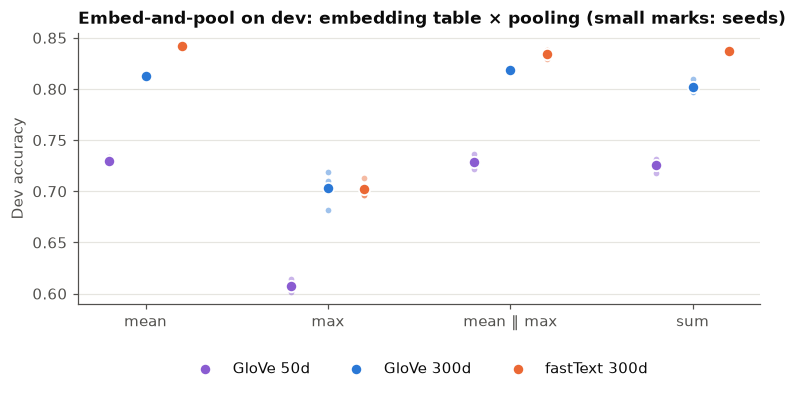

In [17]:
POOLINGS = ("mean", "max", "meanmax", "sum")
variants = {f"{emb} · {pooling}": {**POOL_BASE, "embedding": emb, "pooling": pooling} for emb in EMBEDDINGS for pooling in POOLINGS}
free_inputs()
stage1 = run_dev("pool-1", variants)
# Order: the small table first, then the tutorial's GloVe, then the alternatives (a switch must gain more than the ROPE);
# within a table mean, max, mean‖max, then sum (not normalised by length).
chosen = choose(stage1)
show(stage1, chosen)
EMBEDDING, POOLING = chosen.split(" · ")
POOL_BASE.update(embedding=EMBEDDING, pooling=POOLING)

fig, ax = plt.subplots(figsize=(8, 3.2))
for i, emb in enumerate(EMBEDDINGS):
    for j, pooling in enumerate(POOLINGS):
        row = stage1.loc[f"{emb} · {pooling}"]
        accs = [float(a) for a in row["per seed"].split()]
        x = j + (i - 1) * 0.2
        ax.scatter([x] * len(accs), accs, s=14, color=EMB_COLOR[emb], alpha=0.45, linewidths=0)
        ax.scatter(x, row["dev_accuracy"], s=55, color=EMB_COLOR[emb], edgecolors="white", linewidths=1.2, zorder=3, label=EMBEDDINGS[emb]["label"] if j == 0 else None)
ax.set_xticks(range(len(POOLINGS)), ["mean", "max", "mean ‖ max", "sum"])
ax.set(ylabel="Dev accuracy", title="Embed-and-pool on dev: embedding table × pooling (small marks: seeds)")
tidy(ax); ax.legend(frameon=False, ncols=3, loc="lower center", bbox_to_anchor=(0.5, -0.32))
fig.savefig(FIGURES / "pool_tables_pooling.png"); plt.show()

**Result.** fastText with mean pooling is best (0.842), ahead of GloVe 300d (0.818 with mean ‖ max) and far ahead of
GloVe 50d (about 0.73). So the probe's ranking holds on the task, and **embedding size matters a lot**: from the same
corpus, 50 dimensions lose 9 points to 300. fastText's missing `n't` costs less than its better vectors gain; section 7
checks this again with a model that reads word order. **Max pooling is poor** everywhere (0.61–0.71): one extreme
value per dimension is a noisy summary of a 270-token review. Frozen models vary little between seeds (SD ≤ 0.007, mostly ≤ 0.002), so
differences of a point between settings are real.

### Stage 2: token filter

In [18]:
variants = {f: {**POOL_BASE, "filter": f} for f in FILTERS}
free_inputs()
stage2 = run_dev("pool-2", variants)
chosen = choose(stage2, ["all", "no-punct", "no-stopwords-but-sentiment", "no-stopwords"])  # the least processing first
show(stage2, chosen)
POOL_BASE["filter"] = chosen

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
all,,0.8424,0.0004,0.8420 0.8428 0.8424,4.3333,0.0533
no-punct,,0.8423,0.0008,0.8432 0.8416 0.8420,3.3333,0.0389
no-stopwords,,0.8432,0.0011,0.8420 0.8436 0.8440,5.3333,0.0539
no-stopwords-but-sentiment,← chosen,0.8476,0.0007,0.8484 0.8472 0.8472,5.0000,0.0472


**Result.** Removing the NLTK stopwords changes nothing (0.8432 against 0.8424), because the list also removes `not`,
`no` and `but`. Removing the other stopwords but keeping those sentiment-bearing ones gains 0.5 points (0.8476), just
over the ROPE. In a mean, hundreds of function words dilute the few opinion words, and the filter concentrates the
average on content without losing negation. Punctuation doesn't matter.

### Stage 3: output network

Width (the tutorial's 50/50, or 256/128), dropout (0.1, 0.5) and learning rate (1e-3, 3e-4). Narrow before wide, low
dropout before high, the faster learning rate first.

In [19]:
variants = {}
for hidden in ([50, 50], [256, 128]):
    for dropout in (0.1, 0.5):
        for lr in (1e-3, 3e-4):
            variants[f"{hidden[0]}/{hidden[1]}, dropout {dropout}, lr {lr:g}"] = {**POOL_BASE, "hidden": hidden, "dropout": dropout, "lr": lr}
free_inputs()
stage3 = run_dev("pool-3", variants)
chosen = choose(stage3)
show(stage3, chosen)
POOL_BASE.update(hidden=variants[chosen]["hidden"], dropout=variants[chosen]["dropout"], lr=variants[chosen]["lr"])

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
"50/50, dropout 0.1, lr 0.001",← chosen,0.8476,0.0007,0.8484 0.8472 0.8472,5.0000,0.0472
"50/50, dropout 0.1, lr 0.0003",,0.8480,0.0007,0.8488 0.8476 0.8476,11.6667,0.1317
"50/50, dropout 0.5, lr 0.001",,0.8303,0.0070,0.8360 0.8324 0.8224,4.6667,0.0972
"50/50, dropout 0.5, lr 0.0003",,0.8355,0.0032,0.8388 0.8352 0.8324,10.6667,0.1156
"256/128, dropout 0.1, lr 0.001",,0.8473,0.0012,0.8484 0.8476 0.8460,4.0000,0.0650
"256/128, dropout 0.1, lr 0.0003",,0.8463,0.0008,0.8456 0.8472 0.8460,4.0000,0.0600
"256/128, dropout 0.5, lr 0.001",,0.8283,0.0019,0.8304 0.8268 0.8276,4.0000,0.0911
"256/128, dropout 0.5, lr 0.0003",,0.8376,0.0014,0.8392 0.8372 0.8364,7.6667,0.1067


**Result.** No wider, slower or more regularised network beats the tutorial's setting (50/50, dropout 0.1, lr 1e-3) by
more than 0.1 point. Dropout 0.5 costs 1–2 points: with frozen inputs the network does not over-fit, so more
regularisation only removes signal. The output network is not where the gains are.

### Stage 4: frozen, fine-tuned or random embeddings

Fine-tuning updates all ~90,000 × 300 embedding weights (27 million). The random variant keeps the same vocabulary and the same
scale but starts from noise, which isolates what pretraining contributes. Both need the full encoder in every step
(no precomputed vectors), so these fits are much slower. With millions of trainable weights the learning rate chosen
for the frozen model may be too high, so both trainable variants also get the slower rate.

In [20]:
variants = {"frozen": POOL_BASE}
for lr in (1e-3, 3e-4):
    variants[f"fine-tuned, lr {lr:g}"] = {**POOL_BASE, "train_embeddings": True, "lr": lr}
for lr in (1e-3, 3e-4):
    variants[f"random, trained, lr {lr:g}"] = {**POOL_BASE, "init": "random", "train_embeddings": True, "lr": lr}
free_inputs()
stage4 = run_dev("pool-4", variants)
chosen = choose(stage4)  # frozen, then fine-tuned, then random
show(stage4, chosen)
POOL_FINAL = variants[chosen]
print("Selected embed-and-pool configuration:", POOL_FINAL)

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
frozen,,0.8476,0.0007,0.8484 0.8472 0.8472,5.0,0.0472
"fine-tuned, lr 0.001",← chosen,0.8901,0.0020,0.8904 0.8880 0.8920,1.0,1.4089
"fine-tuned, lr 0.0003",,0.8909,0.0012,0.8920 0.8912 0.8896,2.0,7.3972
"random, trained, lr 0.001",,0.8885,0.0027,0.8872 0.8868 0.8916,1.0,1.4017
"random, trained, lr 0.0003",,0.8841,0.0014,0.8828 0.8856 0.8840,2.0,0.1133


Selected embed-and-pool configuration: {'encoder': 'pool', 'embedding': 'fasttext', 'filter': 'no-stopwords-but-sentiment', 'pooling': 'mean', 'init': 'pretrained', 'train_embeddings': True, 'hidden': [50, 50], 'dropout': 0.1, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 64, 'max_epochs': 30, 'patience': 3}


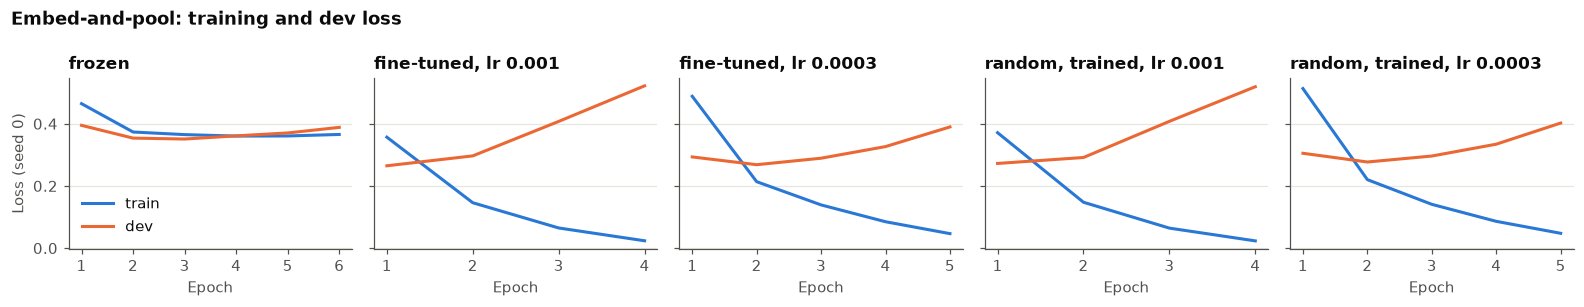

In [21]:
fig, axes = plt.subplots(1, len(variants), figsize=(2.9 * len(variants), 2.8), sharey=True)
for ax, (name, config) in zip(axes, variants.items()):
    h = history_of(config)
    ax.plot(h["epoch"] + 1, h["train_loss"], color=BLUE, linewidth=2, label="train")
    ax.plot(h["epoch"] + 1, h["dev_loss"], color=ORANGE, linewidth=2, label="dev")
    ax.set(title=name, xlabel="Epoch"); tidy(ax)
axes[0].set_ylabel("Loss (seed 0)"); axes[0].legend(frameon=False)
fig.suptitle("Embed-and-pool: training and dev loss", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGURES / "pool_embedding_training.png"); plt.show()

**Result.** Training the embeddings is by far the largest gain in the embed-and-pool search: **+4.3 points** (0.848 →
0.890). Both learning rates are equal within the seed spread, so the faster one is kept. **Random embeddings trained
from scratch do almost as well** (0.889): with 22,000 labelled reviews the task can learn its own word vectors, and the
pretrained start adds little at the end point. The learning curves in section 7 ask when it does matter.

Trained embeddings **over-fit fast**. Dev loss is lowest after 1 epoch (2 at the slower rate), and from then on training
loss falls while dev loss rises (figure). The model has 29 million trainable weights for 22,000 reviews, so early
stopping on dev is what keeps it usable.

## 7. Recurrent encoders

Recurrent fits take minutes, not seconds, so the search is narrower. Each stage tries one group of choices with
**one seed**. The starting configuration is fitted **with all three seeds**, to show how much a single-seed
difference can be trusted. The final configuration is refitted with all three seeds before it goes to
cross-validation.

The starting point follows the tutorial's LSTM: unidirectional, last state, frozen embeddings (the table chosen in
section 6), word dropout 0.1, the tutorial's output network. It uses a larger state (128) and cuts reviews at 400
tokens, which keeps all of 82% of reviews.

In [22]:
RNN_BASE = dict(encoder="lstm", embedding=EMBEDDING, filter="all", init="pretrained", train_embeddings=False, hidden_size=128,
                bidirectional=False, readout="last", word_dropout=0.1, max_len=400, truncation="head",
                hidden=[50, 50], dropout=0.1, lr=1e-3, weight_decay=1e-4, batch_size=64, max_epochs=20, patience=3, clip=1.0)
base = run_dev("rnn-0", {"LSTM, starting point": RNN_BASE})
show(base)
SEED_SD = base["sd over seeds"].iloc[0]
print(f"Seed-to-seed SD of dev accuracy for the starting point: {SEED_SD:.4f}")

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
"LSTM, starting point",,0.8848,0.0056,0.8876 0.8784 0.8884,11.0,0.3011


Seed-to-seed SD of dev accuracy for the starting point: 0.0056


The starting point's seed-to-seed SD is **0.0056**, larger than the ROPE. A difference between two single-seed results
needs to be about a point (two SDs) before it means much, and the stages below are read with that in mind.

### Stage 1: architecture

Cell (LSTM, GRU), direction (one or both) and readout (last state, or max over all states). Order of simplicity: GRU
before LSTM (fewer weights), unidirectional before bidirectional, last state before max.

In [23]:
variants = {}
for bidirectional in (False, True):
    for readout in ("last", "max"):
        for cell in ("gru", "lstm"):
            name = f"{'Bi' if bidirectional else ''}{cell.upper()}, {readout}"
            variants[name] = {**RNN_BASE, "encoder": cell, "bidirectional": bidirectional, "readout": readout}
free_inputs()
rnn1 = run_dev("rnn-1", variants, seeds=(0,))
chosen = choose(rnn1)
show(rnn1, chosen)
RNN_BASE.update(encoder=variants[chosen]["encoder"], bidirectional=variants[chosen]["bidirectional"], readout=variants[chosen]["readout"])

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
"GRU, last",,0.8940,NaN,0.8940,9.0,0.2283
"LSTM, last",,0.8876,NaN,0.8876,11.0,0.3050
"GRU, max",← chosen,0.9000,NaN,0.9000,5.0,0.1517
"LSTM, max",,0.8924,NaN,0.8924,4.0,0.1500
"BiGRU, last",,0.8868,NaN,0.8868,7.0,0.2800
"BiLSTM, last",,0.8800,NaN,0.8800,11.0,0.4867
"BiGRU, max",,0.8968,NaN,0.8968,3.0,0.1650
"BiLSTM, max",,0.8940,NaN,0.8940,3.0,0.2083


**Result.** The **max readout** helps every architecture (+0.5 to +1.4 points over the last state) and needs fewer
epochs. A max over all states lets the classifier use strong evidence wherever it occurs. The last state has to carry
that evidence through hundreds of steps. Reading in both directions adds nothing. The GRU with max readout scores highest
and is also the simplest of the max-readout variants. Its lead over LSTM-max and BiGRU-max (0.3–0.8 points) is within
single-seed noise, so the honest conclusion is "max readout matters, the cell and direction don't".

### Stage 2: how much of the review to read

17% of reviews are longer than 400 tokens. Shorter limits are faster. Keeping the *end* instead of the start could
help, because reviewers often state their verdict at the end.

In [24]:
variants = {
    "first 256": {**RNN_BASE, "max_len": 256},
    "first 400": RNN_BASE,
    "last 400": {**RNN_BASE, "truncation": "tail"},
    "first 100 + last 300": {**RNN_BASE, "truncation": "head+tail"},
    "first 800": {**RNN_BASE, "max_len": 800},
}
free_inputs()
rnn2 = run_dev("rnn-2", variants, seeds=(0,))
chosen = choose(rnn2)  # listed cheapest first; the three 400-token variants cost the same
show(rnn2, chosen)
RNN_BASE.update(max_len=variants[chosen]["max_len"], truncation=variants[chosen]["truncation"])

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
first 256,,0.8848,NaN,0.8848,4.0,0.1283
first 400,← chosen,0.9000,NaN,0.9000,5.0,0.1517
last 400,,0.9020,NaN,0.9020,4.0,0.1317
first 100 + last 300,,0.9040,NaN,0.9040,5.0,0.1500
first 800,,0.9024,NaN,0.9024,5.0,0.1583


**Result.** Cutting reviews at 256 tokens costs 1.5 points. All variants that read 400 tokens or more are within 0.4
points of each other (0.900–0.904), so keeping the end, or reading 800 tokens, is not reliably better. The cheapest,
the first 400 tokens, stays. The idea that the verdict sits at the end gets at most weak support.

### Stage 3: embedding parameters

The other frozen tables (the 50-dimensional one for embedding size; GloVe 300d, whose tokens match ours, in case word
order makes the `n't` problem matter more), then fine-tuned and random embeddings at both learning rates, as for
embed-and-pool.

In [25]:
variants = {f"{name}, frozen": {**RNN_BASE, "embedding": name} for name in [EMBEDDING] + [e for e in EMBEDDINGS if e != EMBEDDING]}
for lr in (1e-3, 3e-4):
    variants[f"{EMBEDDING}, fine-tuned, lr {lr:g}"] = {**RNN_BASE, "train_embeddings": True, "lr": lr}
for lr in (1e-3, 3e-4):
    variants[f"random, trained, lr {lr:g}"] = {**RNN_BASE, "init": "random", "train_embeddings": True, "lr": lr}
free_inputs()
rnn3 = run_dev("rnn-3", variants, seeds=(0,))
chosen = choose(rnn3)  # frozen tables first, then fine-tuned, then random
show(rnn3, chosen)
RNN_BASE.update({key: variants[chosen][key] for key in ("embedding", "init", "train_embeddings", "lr")})

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
"fasttext, frozen",← chosen,0.9000,NaN,0.9000,5.0,0.1517
"glove-50, frozen",,0.8796,NaN,0.8796,10.0,0.2467
"glove-300, frozen",,0.8936,NaN,0.8936,4.0,0.1317
"fasttext, fine-tuned, lr 0.001",,0.8960,NaN,0.8960,2.0,0.1567
"fasttext, fine-tuned, lr 0.0003",,0.8804,NaN,0.8804,2.0,0.1567
"random, trained, lr 0.001",,0.8960,NaN,0.8960,2.0,0.1617
"random, trained, lr 0.0003",,0.8800,NaN,0.8800,2.0,0.1600


**Result.** fastText is again the best frozen table (GloVe 300d −0.6 points, GloVe 50d −2.0). Even for a model that
reads word order, the missing `n't` doesn't hurt enough to change the choice. **Fine-tuning does not help the GRU**
(0.896 at lr 1e-3, 0.880 at 3e-4, against 0.900 frozen), unlike embed-and-pool. The recurrent layer can already
reshape the representation, and trainable embeddings make it over-fit. Random embeddings at lr 1e-3 equal the
fine-tuned ones (0.896).

**Over-fitting.** Loss curves of the stage-3 fits:

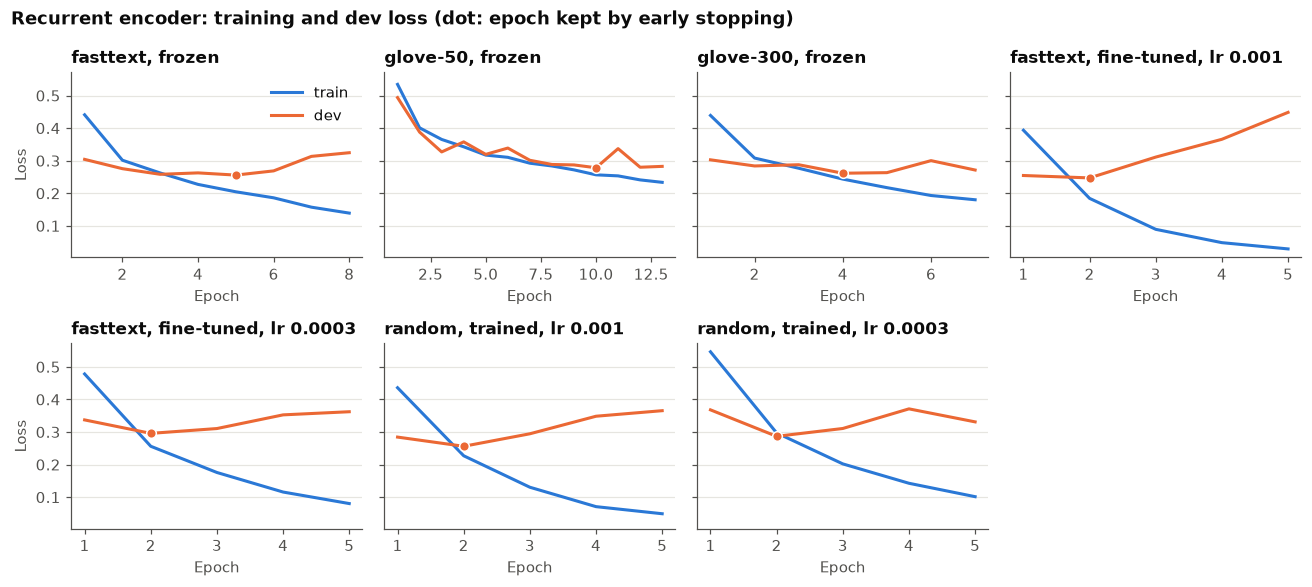

In [26]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.4), sharey=True)
axes = axes.ravel()
for ax in axes[len(variants):]:
    ax.axis("off")
for ax, (name, config) in zip(axes, variants.items()):
    h = history_of(config)
    ax.plot(h["epoch"] + 1, h["train_loss"], color=BLUE, linewidth=2, label="train")
    ax.plot(h["epoch"] + 1, h["dev_loss"], color=ORANGE, linewidth=2, label="dev")
    best = h["dev_loss"].idxmin()
    ax.scatter(best + 1, h["dev_loss"][best], color=ORANGE, s=40, zorder=3, edgecolors="white")
    ax.set(title=name, xlabel="Epoch"); tidy(ax)
axes[0].set_ylabel("Loss"); axes[4].set_ylabel("Loss"); axes[0].legend(frameon=False)
fig.suptitle("Recurrent encoder: training and dev loss (dot: epoch kept by early stopping)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGURES / "rnn_embedding_training.png"); plt.show()

**Did we struggle with over-fitting?** Yes, whenever embeddings were trained. With fine-tuned or random embeddings the
dev loss is lowest after epoch 2 and then climbs while training loss keeps falling. With frozen tables the model
improves for 4–10 epochs. Early stopping on dev, word dropout and frozen embeddings are what controlled it.

### Stage 4: capacity and regularisation

State size and word dropout, the regulariser the tutorial recommends for RNNs.

In [27]:
variants = {
    "state 64": {**RNN_BASE, "hidden_size": 64},
    "state 128": RNN_BASE,
    "state 256": {**RNN_BASE, "hidden_size": 256},
    "word dropout 0": {**RNN_BASE, "word_dropout": 0.0},
    "word dropout 0.3": {**RNN_BASE, "word_dropout": 0.3},
    "output dropout 0.5": {**RNN_BASE, "dropout": 0.5},
}
free_inputs()
rnn4 = run_dev("rnn-4", variants, seeds=(0,))
chosen = choose(rnn4)
show(rnn4, chosen)
RNN_FINAL = variants[chosen]
final = run_dev("rnn-final", {"final": RNN_FINAL})
show(final)
print("Selected recurrent configuration:", RNN_FINAL)
print(f"Trainable parameters: embed-and-pool {count_parameters(POOL_FINAL):,}; recurrent {count_parameters(RNN_FINAL):,}")

,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
state 64,,0.8884,NaN,0.8884,5.0,0.1467
state 128,← chosen,0.9000,NaN,0.9000,5.0,0.1517
state 256,,0.9000,NaN,0.9000,3.0,0.3033
word dropout 0,,0.8852,NaN,0.8852,5.0,0.1433
word dropout 0.3,,0.8924,NaN,0.8924,4.0,0.1317
output dropout 0.5,,0.8824,NaN,0.8824,4.0,0.1317


,,dev_accuracy,sd over seeds,per seed,best epoch,minutes per fit
variant,,,,,,
final,,0.8963,0.0034,0.9000 0.8932 0.8956,4.3333,0.1378


Selected recurrent configuration: {'encoder': 'gru', 'embedding': 'fasttext', 'filter': 'all', 'init': 'pretrained', 'train_embeddings': False, 'hidden_size': 128, 'bidirectional': False, 'readout': 'max', 'word_dropout': 0.1, 'max_len': 400, 'truncation': 'head', 'hidden': [50, 50], 'dropout': 0.1, 'lr': 0.001, 'weight_decay': 0.0001, 'batch_size': 64, 'max_epochs': 20, 'patience': 3, 'clip': 1.0}
Trainable parameters: embed-and-pool 29,136,902; recurrent 174,222


**Result.** A state of 128 is enough: 64 is worse, 256 equal. Removing word dropout (−1.5 points) or raising output
dropout to 0.5 (−1.8) hurts, word dropout 0.3 a little (−0.8), so the starting settings stay. Refitted with 3 seeds, the
final GRU scores 0.896 ± 0.003 on dev, below its single-seed 0.900. That is the expected cost of picking a winner on
one seed. It has 174,000 trainable weights, about 170 times fewer than the fine-tuned embed-and-pool model.

### Data size and pretraining

When does pretraining matter? A learning curve on dev (3 seeds, each a different random subset of the pool) for both
encoders, each with pretrained and with random embeddings. The usual expectation is that pretrained vectors matter
most when labelled data are scarce.

system,"Embed-and-pool, pretrained","Embed-and-pool, random","Recurrent, pretrained","Recurrent, random"
reviews,,,,
1120,0.8303,0.8196,0.8364,0.7861
3360,0.8589,0.8517,0.8615,0.8461
8961,0.8745,0.8717,0.8767,0.8680
22402,0.8901,0.8885,0.8963,0.8993


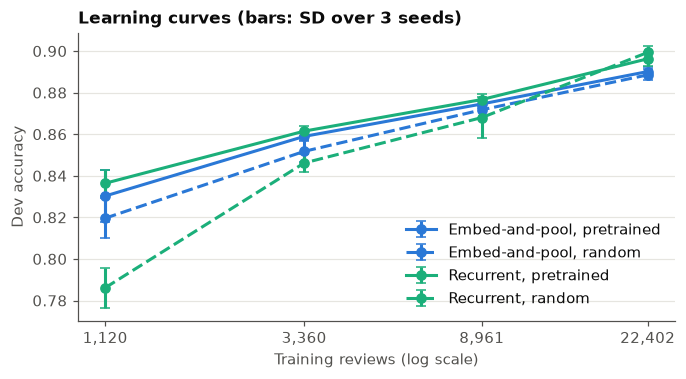

In [28]:
FRACTIONS = (0.05, 0.15, 0.4, 1.0)
curves = {
    "Embed-and-pool, pretrained": POOL_FINAL,
    "Embed-and-pool, random": {**POOL_FINAL, "init": "random", "train_embeddings": True},
    "Recurrent, pretrained": RNN_FINAL,
    "Recurrent, random": {**RNN_FINAL, "init": "random", "train_embeddings": True},
}
free_inputs()
curve_rows = []
for name, config in curves.items():
    for fraction in FRACTIONS:
        summary = run_dev("curve", {name: config}, fraction=fraction)
        curve_rows.append({"system": name, "fraction": fraction, "reviews": round(fraction * len(data.pool_texts)),
                           "dev_accuracy": summary["dev_accuracy"].iloc[0], "sd": summary["sd over seeds"].iloc[0]})
curve = pd.DataFrame(curve_rows)
display(curve.pivot(index="reviews", columns="system", values="dev_accuracy").round(4))

fig, ax = plt.subplots(figsize=(7, 3.4))
styles = {"Embed-and-pool, pretrained": (BLUE, "-"), "Embed-and-pool, random": (BLUE, "--"), "Recurrent, pretrained": (GREEN, "-"), "Recurrent, random": (GREEN, "--")}
for name, rows in curve.groupby("system", sort=False):
    color, line = styles[name]
    ax.errorbar(rows["reviews"], rows["dev_accuracy"], yerr=rows["sd"], color=color, linestyle=line, marker="o", linewidth=2, capsize=3, label=name)
ax.set_xscale("log"); ax.set_xticks(curve["reviews"].unique(), [f"{n:,}" for n in curve["reviews"].unique()])
ax.minorticks_off()
ax.set(xlabel="Training reviews (log scale)", ylabel="Dev accuracy", title="Learning curves (bars: SD over 3 seeds)")
tidy(ax); ax.legend(frameon=False)
fig.savefig(FIGURES / "learning_curves.png"); plt.show()

**Result.** Pretraining matters when labelled data are scarce, and most for the recurrent encoder. With 1,120 reviews,
pretrained vectors add **5 points** to the GRU (0.836 against 0.786) and 1 point to embed-and-pool (0.830 against 0.820).
The gap shrinks as data grow, and with all 22,402 reviews it is gone (embed-and-pool 0.890 against 0.889; GRU 0.896
against 0.899, random slightly ahead). The pretrained GRU keeps its embeddings frozen while the random one trains them.
On a dataset of this size, the main value of pretrained embeddings is **data efficiency**, not a higher ceiling.

## 8. Cross-validation

The two selected configurations go through Project 1's protocol: 5 folds × 3 seeds, the torch seed `seed × 1000 +
fold`, early stopping on dev. Validation predictions are saved for error analysis.

**Test predictions are made now and sealed.** Project 1 refitted the selected system's 15 models for the test. Here
that would mean training 30 more models, and storing the models instead would take about 2 GB
when embeddings are fine-tuned. So each fold model predicts the test set right after training. The log-probabilities
go to `cache.nosync/sealed_test_*/`, nothing is scored, and section 10 opens only the selected system's files.

Because the folds are identical, Project 1's nine systems join the comparison directly from `results/cv_scores.csv`.

In [29]:
SYSTEMS = {"pool": POOL_FINAL, "rnn": RNN_FINAL}  # simplest first
CV_SCORES = RESULTS / "cv_scores.csv"
system_file = RESULTS / "cv_systems.json"
saved_systems = json.loads(system_file.read_text()) if system_file.exists() else {}
for system, config in SYSTEMS.items():
    assert saved_systems.get(system, config) == config, f"{system} changed since its CV scores were saved; delete them to rerun"
system_file.write_text(json.dumps({**saved_systems, **SYSTEMS}, indent=2))


def sealed_path(system, seed, fold):
    return SEALED / f"{system}_s{seed}_f{fold}.npy"


def run_cv(systems):
    """Cross-validate systems. Skips (system, seed, fold) already in CV_SCORES, so an interrupted run resumes."""
    done = set()
    if CV_SCORES.exists():
        done = {(r.system, int(r.seed), int(r.fold)) for r in pd.read_csv(CV_SCORES).itertuples()}
    for seed in SEEDS:
        for fold, (train_ids, val_ids) in fold_ids(seed).items():
            for system, config in systems.items():
                if (system, seed, fold) in done:
                    continue
                model, info = fit_on_pool(config, train_ids, seed * 1000 + fold)
                logprobs = predict_logprobs(model, config, model_inputs(config, "pool", val_ids))
                predictions = logprobs.argmax(1)
                np.savez_compressed(RESULTS / "cv_predictions" / f"{system}_s{seed}_f{fold}.npz", ids=val_ids, predictions=predictions, p_positive=np.exp(logprobs[:, 1]))
                np.save(sealed_path(system, seed, fold), predict_logprobs(model, config, model_inputs(config, "test")))  # not scored here
                labels = data.pool_labels[val_ids]
                append_row(CV_SCORES, {"system": system, "seed": seed, "fold": fold, "accuracy": float((predictions == labels).mean()),
                                       "macro_f1": f1_score(labels, predictions, average="macro"), "best_epoch": info["best_epoch"],
                                       "fit_seconds": round(info["fit_seconds"], 1)})
                print(f"{system} seed {seed} fold {fold}: accuracy {(predictions == labels).mean():.4f} ({info['fit_seconds'] / 60:.1f} min)")
    return pd.read_csv(CV_SCORES)


free_inputs()
cv = run_cv(SYSTEMS)
assert (cv.groupby("system").size() == len(SEEDS) * NUM_FOLDS).all()

P1_NAMES = {"logistic": "P1 log-linear", "mlp": "P1 MLP (1 hidden)", "deep-mlp": "P1 MLP (2 hidden)"}
P1_REPS = {"indicator": "token indicator", "bow": "bag-of-words", "tfidf": "TF-IDF"}
p1_cv = pd.read_csv(P1_RESULTS / "cv_scores.csv")
p1_cv["system"] = "p1:" + p1_cv["system"]
columns = ["system", "seed", "fold", "accuracy", "macro_f1"]
cv_all = pd.concat([p1_cv[columns], cv[columns]], ignore_index=True)


def label(system):
    if system.startswith("p1:"):
        arch, rep = system[3:].split("_")
        return f"{P1_NAMES[arch]} · {P1_REPS[rep]}"
    config = SYSTEMS[system]
    if system == "pool":
        how = "random" if config["init"] == "random" else "fine-tuned" if config["train_embeddings"] else "frozen"
        return f"Embed-and-pool · {config['pooling']} · {config['embedding']} ({how})"
    cell = ("Bi" if config["bidirectional"] else "") + config["encoder"].upper()
    how = "random" if config["init"] == "random" else "fine-tuned" if config["train_embeddings"] else "frozen"
    return f"{cell} · {config['readout']} · {config['embedding']} ({how})"


table = cv_all.groupby("system").agg(accuracy=("accuracy", "mean"), sd=("accuracy", "std"), macro_f1=("macro_f1", "mean"))
table = table.sort_values("accuracy", ascending=False)
table.index = [label(s) for s in table.index]
display(table.round(4))

,accuracy,sd,macro_f1
Embed-and-pool · mean · fasttext (fine-tuned),0.8961,0.0064,0.8960
GRU · max · fasttext (frozen),0.8936,0.0048,0.8935
P1 MLP (1 hidden) · TF-IDF,0.8913,0.0036,0.8913
P1 MLP (2 hidden) · TF-IDF,0.8911,0.0045,0.8911
P1 MLP (1 hidden) · bag-of-words,0.8885,0.0046,0.8885
P1 MLP (2 hidden) · bag-of-words,0.8874,0.0049,0.8874
P1 MLP (1 hidden) · token indicator,0.8846,0.0046,0.8846
P1 MLP (2 hidden) · token indicator,0.8839,0.0048,0.8839
P1 log-linear · TF-IDF,0.8813,0.0053,0.8812
P1 log-linear · bag-of-words,0.8723,0.0051,0.8723


**Result.** Both new systems score above every Project 1 system: embed-and-pool 0.8961 and the GRU 0.8936, against
0.8913 for Project 1's top scorer (MLP on TF-IDF) and 0.8885 for its selected system (MLP on bag-of-words). The
fold-to-fold SD (0.005–0.006) is larger than these gaps, which is why section 9 compares systems pairwise on matched
folds.

**Reproducibility:** refitting one stored fold should give the same predictions. Models trained on a GPU (cuDNN on
CUDA, or MPS) are not guaranteed to be bit-for-bit deterministic, so the agreement rate is reported. The check runs once and is saved.
In the recorded run, on CUDA, both refits reproduced the stored predictions exactly.

In [30]:
reproducibility_path = RESULTS / "reproducibility.json"
if not reproducibility_path.exists():
    train_ids, val_ids = fold_ids(3)[1]
    checks = {}
    for system, config in SYSTEMS.items():
        model, _ = fit_on_pool(config, train_ids, 3 * 1000 + 1)
        refit = predict_logprobs(model, config, model_inputs(config, "pool", val_ids)).argmax(1)
        stored = np.load(RESULTS / "cv_predictions" / f"{system}_s3_f1.npz")["predictions"]
        checks[label(system)] = {"device": str(device_for(config)), "identical predictions": bool((refit == stored).all()),
                                 "agreement": float((refit == stored).mean())}
    reproducibility_path.write_text(json.dumps(checks, indent=2))
display(pd.DataFrame(json.loads(reproducibility_path.read_text())).T)

,device,identical predictions,agreement
Embed-and-pool · mean · fasttext (fine-tuned),cuda,True,1.0
GRU · max · fasttext (frozen),cuda,True,1.0


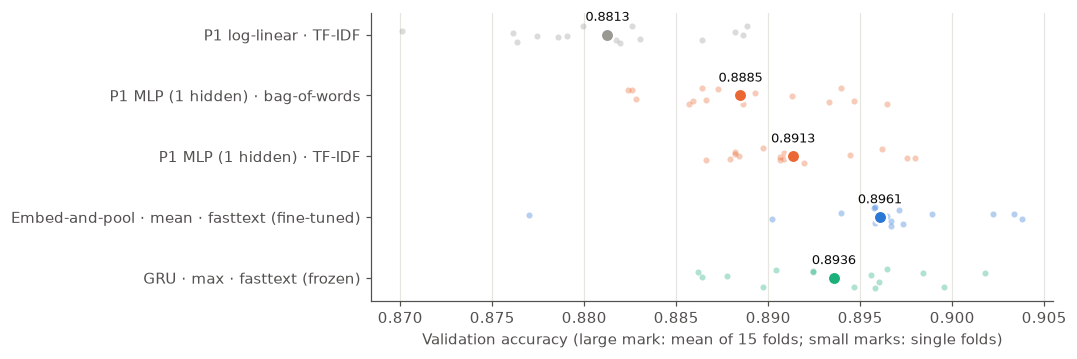

In [31]:
shown = ["p1:logistic_tfidf", "p1:mlp_bow", "p1:mlp_tfidf", "pool", "rnn"]
colors = {"p1:logistic_tfidf": GREY, "p1:mlp_bow": ORANGE, "p1:mlp_tfidf": ORANGE, "pool": BLUE, "rnn": GREEN}
fig, ax = plt.subplots(figsize=(8, 3.4))
rng = np.random.default_rng(0)
for y, system in enumerate(shown[::-1]):
    values = cv_all.loc[cv_all["system"] == system, "accuracy"]
    ax.scatter(values, y + rng.uniform(-0.16, 0.16, len(values)), s=16, alpha=0.35, color=colors[system], linewidths=0)
    ax.scatter(values.mean(), y, s=75, color=colors[system], edgecolors="white", linewidths=1.5, zorder=3)
    ax.annotate(f"{values.mean():.4f}", (values.mean(), y), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5)
ax.set_yticks(range(len(shown)), [label(s) for s in shown[::-1]])
ax.set_xlabel("Validation accuracy (large mark: mean of 15 folds; small marks: single folds)")
tidy(ax, "x")
fig.savefig(FIGURES / "cv_accuracy.png"); plt.show()

## 9. Bayesian comparison and selection

The same correlated Bayesian t-test as in Project 1 (`analysis.BenavoliCorrelatedT` with `runs=3`), ROPE = 0.005.
The pairs are matched on the same 15 validation folds, including those of Project 1's systems.

,A,B,mean B-A,P(A wins),P(tie),P(B wins)
0,Embed-and-pool · mean · fasttext (fine-tuned),GRU · max · fasttext (frozen),-0.0025,0.3013,0.6325,0.0662
1,P1 log-linear · TF-IDF,Embed-and-pool · mean · fasttext (fine-tuned),0.0148,0.0000,0.0059,0.9941
2,P1 MLP (1 hidden) · bag-of-words,Embed-and-pool · mean · fasttext (fine-tuned),0.0076,0.0003,0.1891,0.8106
3,P1 MLP (1 hidden) · TF-IDF,Embed-and-pool · mean · fasttext (fine-tuned),0.0047,0.0026,0.5352,0.4623
4,P1 MLP (1 hidden) · bag-of-words,GRU · max · fasttext (frozen),0.0051,0.0023,0.4880,0.5097
5,P1 MLP (1 hidden) · TF-IDF,GRU · max · fasttext (frozen),0.0022,0.0061,0.8505,0.1434


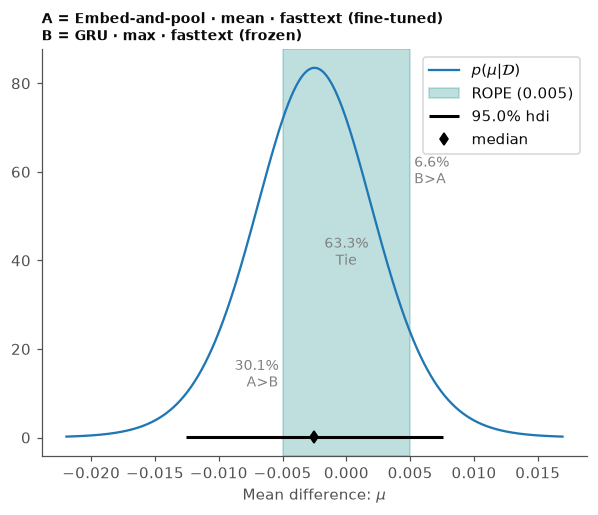

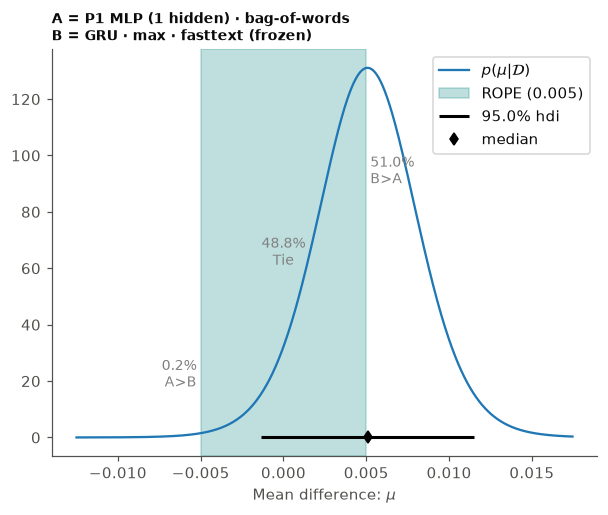

In [32]:
def paired_scores(df, system, metric="accuracy"):
    """Scores in (seed, fold) order, so they pair up across systems."""
    return df[df["system"] == system].sort_values(["seed", "fold"])[metric].to_numpy()


def compare_pair(df, system_a, system_b, metric="accuracy"):
    return analysis.BenavoliCorrelatedT(paired_scores(df, system_a, metric), paired_scores(df, system_b, metric),
                                        runs=df["seed"].nunique(), names=[system_a, system_b])


def contrasts(df, pairs, rope=ROPE):
    rows = []
    for a, b in pairs:
        posterior = compare_pair(df, a, b)
        p_a, p_tie, p_b = posterior.probs(rope)
        rows.append({"A": label(a), "B": label(b), "mean B-A": posterior.mean_diff, "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b})
    return pd.DataFrame(rows).round(4)


display(contrasts(cv_all, [("pool", "rnn"), ("p1:logistic_tfidf", "pool"), ("p1:mlp_bow", "pool"), ("p1:mlp_tfidf", "pool"),
                          ("p1:mlp_bow", "rnn"), ("p1:mlp_tfidf", "rnn")]))
for a, b in [("pool", "rnn"), ("p1:mlp_bow", "rnn")]:
    fig, ax = compare_pair(cv_all, a, b).plot(ROPE)
    ax.set_title(f"A = {label(a)}\nB = {label(b)}", fontsize=9)
    fig.savefig(FIGURES / f"posterior_{a.replace(':', '-')}_vs_{b}.png"); plt.show()

**Result.**

- **Embed-and-pool and the GRU are practically equivalent**: P(tie) 0.63, with embed-and-pool 0.25 points ahead
  (P(it is better) 0.30, P(the GRU is better) 0.07). Word order did not pay off overall.
- **Against Project 1's selected system** (MLP on bag-of-words), embed-and-pool is better by more than the ROPE with
  probability 0.81. For the GRU it is 0.51.
- **Against Project 1's top scorer** (MLP on TF-IDF), embed-and-pool is 0.47 points ahead, with P(better) 0.46 and
  P(tie) 0.54. The GRU ties (0.85).

So pretrained embeddings did add to the design, but by about half a point, right at the edge of what we call a
practical difference.

**Selection rule**, the same as Project 1's: take the simplest system that the top scorer doesn't beat by more than
the ROPE with probability ≥ 0.5. Embed-and-pool is simpler than the recurrent encoder.

In [33]:
def select_system(df, systems, rope=ROPE, metric="accuracy", max_p_worse=0.5):
    """Returns (selected system, top-scoring system); `systems` is ordered simplest first."""
    means = df[df["system"].isin(systems)].groupby("system")[metric].mean()
    best = means.idxmax()
    for system in systems:
        if system == best:
            break
        if compare_pair(df, system, best, metric).probs(rope)[2] < max_p_worse:
            return system, best
    return best, best


rows = []
for rope in (0.0025, 0.005, 0.01):
    selected, best = select_system(cv_all, list(SYSTEMS), rope=rope)
    rows.append({"ROPE": rope, "selected": label(selected), "top scorer": label(best),
                 "P(top scorer wins)": compare_pair(cv_all, selected, best).probs(rope)[2] if selected != best else np.nan})
display(pd.DataFrame(rows).round(4))
SELECTED, TOP = select_system(cv_all, list(SYSTEMS))
print(f"Selected at ROPE {ROPE}: {label(SELECTED)}")

,ROPE,selected,top scorer,P(top scorer wins)
0,0.0025,Embed-and-pool · mean · fasttext (fine-tuned),Embed-and-pool · mean · fasttext (fine-tuned),NaN
1,0.0050,Embed-and-pool · mean · fasttext (fine-tuned),Embed-and-pool · mean · fasttext (fine-tuned),NaN
2,0.0100,Embed-and-pool · mean · fasttext (fine-tuned),Embed-and-pool · mean · fasttext (fine-tuned),NaN


Selected at ROPE 0.005: Embed-and-pool · mean · fasttext (fine-tuned)


## 10. Final test evaluation

Only the selected system is evaluated, once: the sealed test predictions of its 15 fold models are scored,
individually and as a majority vote. Project 1's selected system went through the same protocol, and its test votes
were saved, so the two can be compared on the same test reviews with an exact McNemar test.

In [34]:
test_path, votes_path = RESULTS / "test_results.json", RESULTS / "test_predictions.npz"
if not (test_path.exists() and votes_path.exists()):
    config, single, votes, p_positive = SYSTEMS[SELECTED], [], [], []
    for seed in SEEDS:
        for fold in range(NUM_FOLDS):
            logprobs = np.load(sealed_path(SELECTED, seed, fold))
            votes.append(logprobs.argmax(1)); p_positive.append(np.exp(logprobs[:, 1]))
            single.append(float((votes[-1] == data.test_labels).mean()))
            print(f"seed {seed} fold {fold}: test accuracy {single[-1]:.4f}")
    votes = np.stack(votes)
    majority = (votes.mean(axis=0) > 0.5).astype(np.int64)  # 15 voters, so no ties
    np.savez_compressed(votes_path, majority=majority, votes=votes, p_positive=np.stack(p_positive), labels=data.test_labels)
    test_path.write_text(json.dumps({
        "system": SELECTED, "config": config, "num_models": len(single),
        "single_model_accuracy_mean": float(np.mean(single)), "single_model_accuracy_std": float(np.std(single, ddof=1)),
        "majority_vote": {"accuracy": float((majority == data.test_labels).mean()), "macro_f1": f1_score(data.test_labels, majority, average="macro")},
    }, indent=2))

test_results = json.loads(test_path.read_text())
assert test_results["system"] == SELECTED and test_results["config"] == SYSTEMS[SELECTED], "saved test results belong to a different system"
saved = np.load(votes_path)
votes, majority, gold = saved["votes"], saved["majority"], saved["labels"]
assert (gold == data.test_labels).all()
p1_test = json.loads((P1_RESULTS / "test_results.json").read_text())
p1_majority = np.load(P1_RESULTS / "test_predictions.npz")["majority"]

cv_accuracy = cv.loc[cv["system"] == SELECTED, "accuracy"].mean()
display(pd.DataFrame({
    label(SELECTED): [cv_accuracy, test_results["single_model_accuracy_mean"], test_results["majority_vote"]["accuracy"]],
    label("p1:" + p1_test["system"]): [p1_cv.loc[p1_cv["system"] == "p1:" + p1_test["system"], "accuracy"].mean(),
                                        p1_test["single_model_accuracy_mean"], p1_test["majority_vote"]["accuracy"]],
}, index=["CV, mean of 15 folds", "test, single model (mean of 15)", "test, majority vote of 15"]).round(4))

correct, p1_correct = majority == gold, p1_majority == gold
only_ours, only_p1 = int((correct & ~p1_correct).sum()), int((~correct & p1_correct).sum())
mcnemar = binomtest(only_ours, only_ours + only_p1, 0.5)
print(f"Majority votes on {len(gold):,} test reviews: right only here {only_ours}, right only in Project 1 {only_p1}; "
      f"difference {(correct.mean() - p1_correct.mean()):+.4f}, exact McNemar p = {mcnemar.pvalue:.3g}")
print(f"The two votes agree on {(majority == p1_majority).mean():.3f} of test reviews.")
print(classification_report(gold, majority, target_names=["negative", "positive"], digits=4))
print(pd.DataFrame(confusion_matrix(gold, majority), index=["true neg", "true pos"], columns=["pred neg", "pred pos"]))

,Embed-and-pool · mean · fasttext (fine-tuned),P1 MLP (1 hidden) · bag-of-words
"CV, mean of 15 folds",0.8961,0.8885
"test, single model (mean of 15)",0.8829,0.8803
"test, majority vote of 15",0.8915,0.8853


Majority votes on 24,676 test reviews: right only here 952, right only in Project 1 800; difference +0.0062, exact McNemar p = 0.000307
The two votes agree on 0.929 of test reviews.
              precision    recall  f1-score   support

    negative     0.8810    0.9038    0.8922     12265
    positive     0.9024    0.8793    0.8907     12411

    accuracy                         0.8915     24676
   macro avg     0.8917    0.8915    0.8915     24676
weighted avg     0.8918    0.8915    0.8915     24676

          pred neg  pred pos
true neg     11085      1180
true pos      1498     10913


**Result.** The 15 embed-and-pool models score 0.883 on test on average and **0.8915 as a majority vote**, against 0.880
and 0.8853 for Project 1. On the same 24,676 test reviews the difference of +0.62 points is significant (exact McNemar
p = 0.0003): embed-and-pool is right on 952 reviews where Project 1's vote is wrong, and wrong on 800 where it is right.
The two votes agree on 93% of reviews. Single models score 1.3 points lower on test than in cross-validation (Project 1:
0.8 points). IMDb's test half reviews different films from the training half, and every tuning choice was made on
training-half reviews. Errors are balanced between the classes (recall 0.904 negative, 0.879 positive).

## 11. Error analysis

**Question:** which properties of a review predict that one major design succeeds where another fails? Three designs
are compared: Project 1's selected bag-of-words MLP (no word order, no pretraining), embed-and-pool (pretrained, no
word order) and the recurrent encoder (pretrained, word order).

**Data:** the out-of-fold predictions on the CV pool. Each pool review was predicted once per seed, by a model that
didn't train on it. That gives 22,402 reviews × 3 seeds per system, without touching the test set again.

**Features**, each with the hypothesis it tests:

| Feature | Definition | Hypothesis |
|---|---|---|
| `log length` | log of word tokens | long reviews mix opinions; the RNN may lose track |
| `beyond max_len` | review longer than the RNN's limit | the RNN never sees the rest |
| `oov %` | % of word tokens outside the embedding table | `<unk>` hurts the pretrained models, not bag-of-words |
| `rare %` | % of word tokens seen < 5 times in the pool | rare words have poor or no learned weights |
| `negation /100` | negation words per 100 tokens | order-sensitive: "not good" |
| `contrast /100` | but, however, although, ... per 100 tokens | mixed verdicts; the RNN could weigh the clause after "but" |
| `lexicon agreement` | opinion-lexicon polarity of the review, signed by the gold label | negative = the words point the wrong way (irony, "so bad it's good", plot summaries) |
| `ending agreement` | the same for the last 20% of tokens | does the review end on a clear verdict? |
| `states rating` | contains a rating such as "7/10" (Project 1's finding) | an easy cue for every system |

As in the tutorial, the BDA model also gets the **predicted label** (one-hot), so a system that is better at one
class isn't mistaken for a feature effect.

In [35]:
ANALYSIS_SYSTEMS = {"p1:mlp_bow": P1_RESULTS / "cv_predictions", "pool": RESULTS / "cv_predictions", "rnn": RESULTS / "cv_predictions"}
SHORT = {"p1:mlp_bow": "P1 BoW-MLP", "pool": "Embed-and-pool", "rnn": "Recurrent"}
SYSTEM_COLOR = {"p1:mlp_bow": ORANGE, "pool": BLUE, "rnn": GREEN}


def out_of_fold(folder, system):
    """predictions[s, i]: label given to pool review i by the seed-s model that held it out."""
    predictions = np.full((len(SEEDS), len(data.pool_texts)), -1)
    for s, seed in enumerate(SEEDS):
        for fold in range(NUM_FOLDS):
            saved = np.load(folder / f"{system.removeprefix('p1:')}_s{seed}_f{fold}.npz")
            predictions[s, saved["ids"]] = saved["predictions"]
    assert (predictions >= 0).all()
    return predictions


oof = {system: out_of_fold(folder, system) for system, folder in ANALYSIS_SYSTEMS.items()}
oof_correct = {system: (p == data.pool_labels).astype(int) for system, p in oof.items()}

rating = re.compile(r"\b\d{1,2}(?:\.\d)?\s?(?:/|out of)\s?10\b")
is_word = FILTERS["no-punct"]
in_table = ROWS[RNN_FINAL["embedding"]] != 1
is_rare = pool_counts < 5
is_negation = np.array([w in NEGATIONS for w in corpus.words])
is_contrast = np.array([w in CONTRAST for w in corpus.words])
polarity_of = np.array([1 if w in positive_words else -1 if w in negative_words else 0 for w in corpus.words])


def signed_polarity(ids, sign):
    p = polarity_of[ids]
    return sign * ((p > 0).sum() - (p < 0).sum()) / ((p != 0).sum() + 1)


rows = []
for text, ids, gold_label in zip(data.pool_texts, corpus.ids["pool"], data.pool_labels):
    words = ids[is_word[ids]] if is_word[ids].any() else ids
    n, sign = len(words), 1 if gold_label == 1 else -1
    rows.append({
        "log length": np.log(n), "beyond max_len": int(len(ids) > RNN_FINAL["max_len"]),
        "oov %": 100 * (~in_table[words]).mean(), "rare %": 100 * is_rare[words].mean(),
        "negation /100": 100 * is_negation[ids].sum() / n, "contrast /100": 100 * is_contrast[ids].sum() / n,
        "lexicon agreement": signed_polarity(words, sign), "ending agreement": signed_polarity(words[int(0.8 * n):], sign),
        "states rating": int(bool(rating.search(text))),
    })
features = pd.DataFrame(rows)
FEATURES = list(features.columns)
display(features.describe().T[["mean", "std", "min", "50%", "max"]].round(3))
display(pd.DataFrame({SHORT[s]: [c.mean()] for s, c in oof_correct.items()}, index=["out-of-fold accuracy, all pool reviews"]).round(4))

,mean,std,min,50%,max
log length,5.251,0.645,2.303,5.176,7.820
beyond max_len,0.174,0.379,0.000,0.000,1.000
oov %,1.239,1.213,0.000,0.995,17.259
rare %,1.835,1.699,0.000,1.488,23.944
negation /100,1.683,1.207,0.000,1.530,15.385
contrast /100,1.111,0.867,0.000,1.003,10.000
lexicon agreement,0.197,0.323,-0.938,0.196,0.957
ending agreement,0.158,0.431,-0.923,0.167,0.960
states rating,0.087,0.282,0.000,0.000,1.000


,P1 BoW-MLP,Embed-and-pool,Recurrent
"out-of-fold accuracy, all pool reviews",0.8885,0.8961,0.8936


**Model-free view first:** accuracy within quartiles (or groups) of each feature, for the three systems.

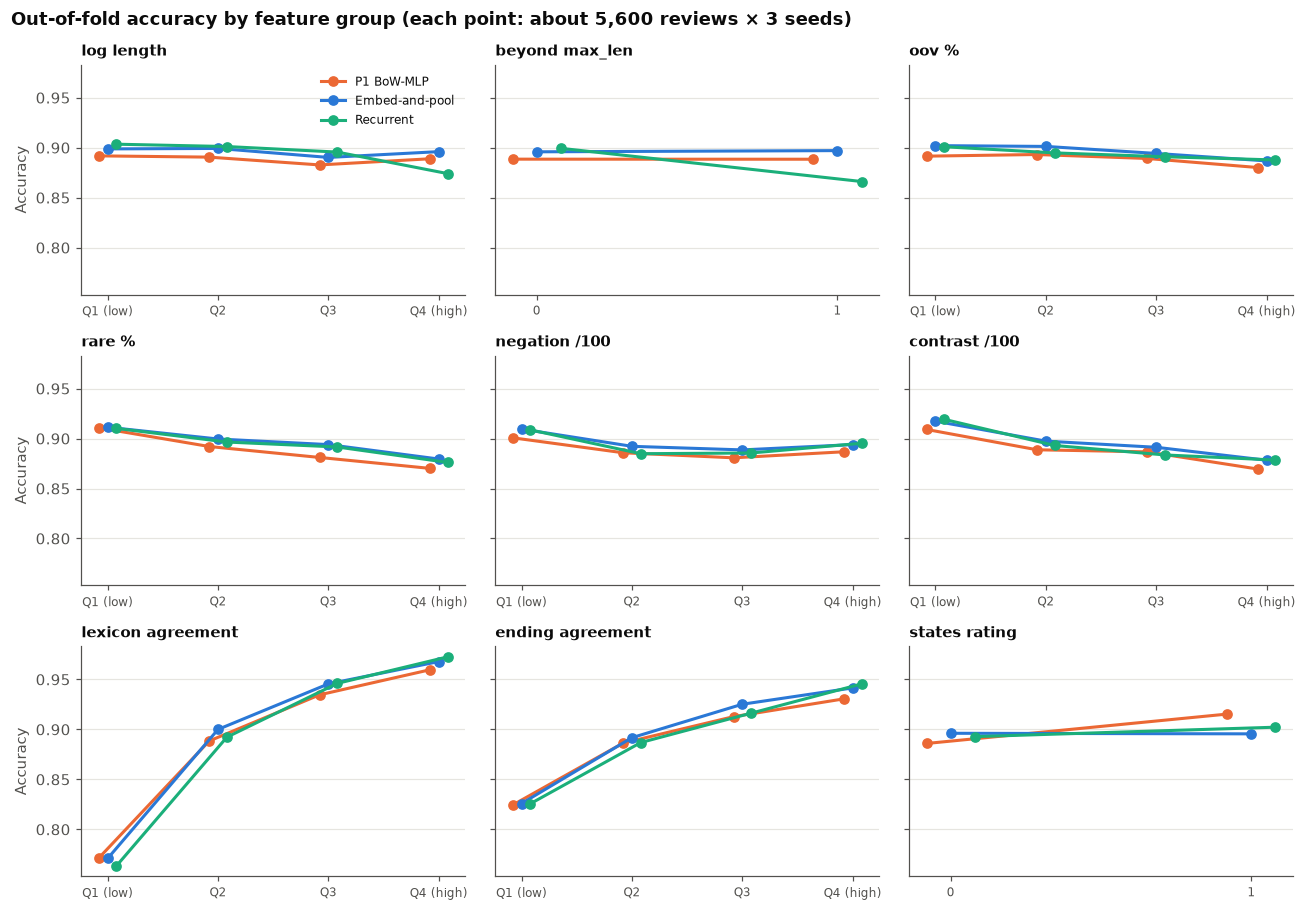

In [36]:
fig, axes = plt.subplots(3, 3, figsize=(12, 8.4), sharey=True)
for ax, feature in zip(axes.flat, FEATURES):
    values = features[feature]
    groups = values.astype(str) if values.nunique() <= 2 else pd.qcut(values.rank(method="first"), 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
    names = sorted(groups.unique()) if values.nunique() <= 2 else ["Q1 (low)", "Q2", "Q3", "Q4 (high)"]
    for k, system in enumerate(ANALYSIS_SYSTEMS):
        accuracy = pd.Series(oof_correct[system].mean(0)).groupby(groups.to_numpy()).mean().reindex(names)
        ax.plot(np.arange(len(names)) + (k - 1) * 0.08, accuracy, marker="o", linewidth=2, color=SYSTEM_COLOR[system], label=SHORT[system])
    ax.set_xticks(range(len(names)), names, fontsize=8); ax.set_title(feature, fontsize=10); tidy(ax)
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Accuracy")
fig.suptitle("Out-of-fold accuracy by feature group (each point: about 5,600 reviews × 3 seeds)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGURES / "accuracy_by_feature.png"); plt.show()

**Bayesian correctness model** (`part2.analysis.fit_bda_model`, the tutorial's model): correctness of system *s* on
review *n* is Bernoulli(sigmoid(φ + δ_s + w_sᵀ f_n)), with Laplace(0, 1) priors on δ and w. The features are
standardised, so each weight is the change in log-odds of being right per standard deviation of the feature. MCMC
on all 200,000 observations would be slow, so 2,500 reviews are sampled at random. That gives 2,500 reviews × 3 seeds
× 3 systems = 22,500 observations.

MCMC: max r_hat 1.004, divergences 0, 7.3 min


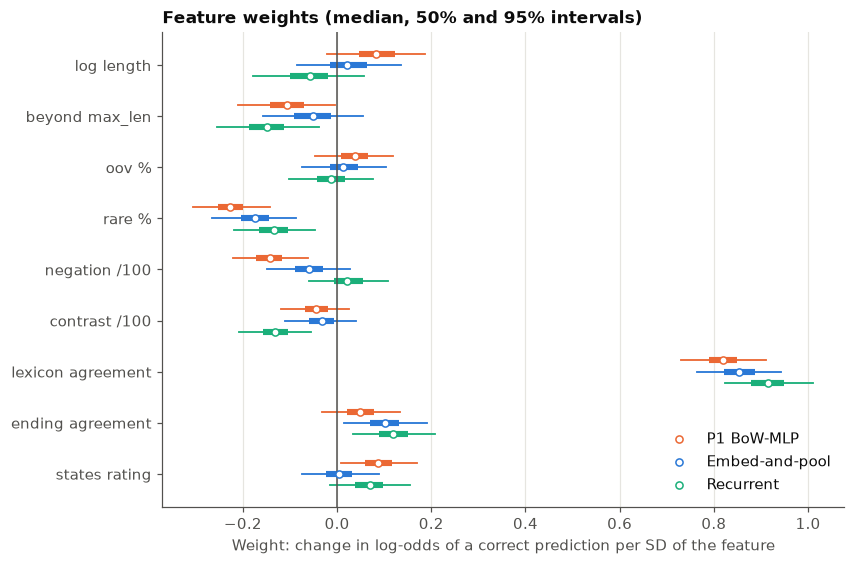

,P1 BoW-MLP,Embed-and-pool,Recurrent
pred: negative,"+0.08 [-1.35, +1.57]","+0.06 [-1.38, +1.70]","+0.07 [-1.64, +1.49]"
pred: positive,"-0.06 [-1.50, +1.44]","-0.06 [-1.50, +1.59]","-0.07 [-1.75, +1.38]"
log length,"+0.08 [-0.02, +0.19]","+0.02 [-0.08, +0.14]","-0.06 [-0.18, +0.06]"
beyond max_len,"-0.11 [-0.21, -0.00]","-0.05 [-0.16, +0.05]","-0.15 [-0.26, -0.04]"
oov %,"+0.04 [-0.05, +0.12]","+0.01 [-0.07, +0.10]","-0.01 [-0.10, +0.08]"
rare %,"-0.23 [-0.31, -0.14]","-0.17 [-0.27, -0.09]","-0.13 [-0.22, -0.05]"
negation /100,"-0.14 [-0.22, -0.06]","-0.06 [-0.15, +0.03]","+0.02 [-0.06, +0.11]"
contrast /100,"-0.04 [-0.12, +0.03]","-0.03 [-0.11, +0.04]","-0.13 [-0.21, -0.05]"
lexicon agreement,"+0.82 [+0.73, +0.91]","+0.85 [+0.76, +0.94]","+0.91 [+0.82, +1.01]"
ending agreement,"+0.05 [-0.03, +0.13]","+0.10 [+0.01, +0.19]","+0.12 [+0.03, +0.21]"


In [37]:
BDA_ITEMS = 2500
bda_path = RESULTS / "bda_posterior.npz"
items = np.sort(np.random.default_rng(0).choice(len(data.pool_texts), BDA_ITEMS, replace=False))
system_names = list(ANALYSIS_SYSTEMS)
feature_names = ["pred: negative", "pred: positive"] + FEATURES
if not bda_path.exists():
    sys_id, feature_rows, correctness = [], [], []
    for s_id, system in enumerate(system_names):
        for s in range(len(SEEDS)):
            sys_id.append(np.full(BDA_ITEMS, s_id))
            feature_rows.append(np.hstack([bda.one_hot(oof[system][s, items], 2), features.loc[items, FEATURES].to_numpy()]))
            correctness.append(oof_correct[system][s, items])
    start = time.time()
    mcmc = bda.fit_bda_model(num_systems=len(system_names), sys_id=np.concatenate(sys_id), features=np.vstack(feature_rows),
                             correctness=np.concatenate(correctness), num_chains=2, num_warmup=500, num_samples=1000, seed=0)
    samples = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items() if k in ("w", "sys_shift", "accuracy", "global_mean")}
    from numpyro.diagnostics import summary as mcmc_summary
    r_hat = max(float(np.max(stats["r_hat"])) for stats in mcmc_summary(samples).values())
    np.savez(bda_path, **samples, r_hat=r_hat, divergences=int(mcmc.get_extra_fields()["diverging"].sum()), minutes=(time.time() - start) / 60)
posterior = np.load(bda_path)
print(f"MCMC: max r_hat {float(posterior['r_hat']):.3f}, divergences {int(posterior['divergences'])}, {float(posterior['minutes']):.1f} min")
w = posterior["w"].reshape(-1, len(system_names), len(feature_names))  # [samples, systems, features]

fig, ax = plt.subplots(figsize=(8, 5.6))
for k, system in enumerate(system_names):
    for j, feature in enumerate(feature_names[2:], start=2):
        draws = w[:, k, j]
        y = len(feature_names) - j + (1 - k) * 0.22
        lo95, lo50, median, hi50, hi95 = np.percentile(draws, [2.5, 25, 50, 75, 97.5])
        ax.plot([lo95, hi95], [y, y], color=SYSTEM_COLOR[system], linewidth=1.2)
        ax.plot([lo50, hi50], [y, y], color=SYSTEM_COLOR[system], linewidth=4, solid_capstyle="butt")
        ax.scatter(median, y, color="white", edgecolors=SYSTEM_COLOR[system], s=22, zorder=3, label=SHORT[system] if j == 2 else None)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks([len(feature_names) - j for j in range(2, len(feature_names))], feature_names[2:])
ax.set(xlabel="Weight: change in log-odds of a correct prediction per SD of the feature", title="Feature weights (median, 50% and 95% intervals)")
tidy(ax, "x"); ax.legend(frameon=False, loc="lower right")
fig.savefig(FIGURES / "bda_weights.png"); plt.show()

weights = pd.DataFrame({SHORT[s]: [f"{np.median(w[:, k, j]):+.2f} [{np.percentile(w[:, k, j], 2.5):+.2f}, {np.percentile(w[:, k, j], 97.5):+.2f}]"
                                   for j in range(len(feature_names))] for k, s in enumerate(system_names)}, index=feature_names)
display(weights)

**Differences between systems** are what the question is about: the posterior of w_RNN − w_BoW and
w_RNN − w_pool for each feature. A positive value means the feature helps the recurrent encoder more (or hurts it
less).

In [38]:
rows = []
for j, feature in enumerate(feature_names[2:], start=2):
    row = {"feature": feature}
    for other in ("p1:mlp_bow", "pool"):
        diff = w[:, system_names.index("rnn"), j] - w[:, system_names.index(other), j]
        row[f"RNN − {SHORT[other]}: median"] = np.median(diff)
        row[f"RNN − {SHORT[other]}: P(> 0)"] = (diff > 0).mean()
    rows.append(row)
display(pd.DataFrame(rows).set_index("feature").round(3))

,RNN − P1 BoW-MLP: median,RNN − P1 BoW-MLP: P(> 0),RNN − Embed-and-pool: median,RNN − Embed-and-pool: P(> 0)
feature,,,,
log length,-0.142,0.032,-0.083,0.158
beyond max_len,-0.041,0.284,-0.097,0.112
oov %,-0.048,0.216,-0.027,0.334
rare %,0.091,0.932,0.040,0.726
negation /100,0.167,0.998,0.080,0.915
contrast /100,-0.088,0.054,-0.100,0.041
lexicon agreement,0.094,0.928,0.060,0.818
ending agreement,0.068,0.882,0.018,0.605
states rating,-0.020,0.364,0.065,0.858


**Result.**

- **Lexicon agreement dominates for every system** (+0.8 to +0.9 log-odds per SD). All three fail mostly where the
  review's opinion words point the other way: irony, "so bad it's good", or plot summaries full of negative words in a
  positive review. No architecture here solves this.
- **Negation is where word order pays off.** More negation words make the bag-of-words MLP less accurate (−0.14
  [−0.22, −0.06]) but not the GRU (+0.02). The difference is positive with probability 0.998 (0.92 against
  embed-and-pool).
- **Contrast words hurt the GRU** (−0.13 [−0.21, −0.05]) more than the other two (P(difference > 0) 0.05 against
  both). A left-to-right GRU with a max readout gives the clause after "but" no special weight, and it may mix both
  judgements.
- **Truncation hurts the GRU** (beyond max_len −0.15), as expected, since it never reads the rest. The BoW MLP also
  does worse on these reviews (−0.11), so long reviews are harder in general.
- **Rare words hurt all three** (−0.23 BoW, −0.17 embed-and-pool, −0.13 GRU). The pretrained systems suffer a little
  less, as expected where bag-of-words has no learned weight. **The OOV rate has no effect**, so fastText's gaps did not
  show up as errors.
- **Stated ratings** help the BoW MLP slightly (+0.09) and not embed-and-pool, for which `7/10` is `<unk>`.
- The predicted-label weights have wide intervals around zero. They are there as controls.

**What we would prioritise next:**

1. Handle contrast and negation scope: a model that sees both sides of "but", such as attention over a bidirectional
   encoder or a pretrained contextual encoder.
2. Read whole reviews (head+tail or hierarchical encoding) for the 17% beyond 400 tokens.
3. Use a tokeniser matched to fastText, or GloVe trained on web text, to keep `n't` and ratings.
4. Lexicon-disagreement errors need more context, not more capacity.

**Reading examples.** Short reviews where the recurrent encoder was right with all three seeds and the bag-of-words MLP
wrong with all three, and the reverse:

In [39]:
def show_examples(winner, loser, k=4, max_words=110):
    wins = np.where((oof_correct[winner].min(0) == 1) & (oof_correct[loser].max(0) == 0) & (lengths <= max_words))[0]
    print(f"{SHORT[winner]} always right, {SHORT[loser]} always wrong: {len(wins)} reviews of ≤ {max_words} tokens "
          f"({((oof_correct[winner].min(0) == 1) & (oof_correct[loser].max(0) == 0)).sum()} of any length)")
    for i in np.random.default_rng(1).choice(wins, size=min(k, len(wins)), replace=False):
        print(f"\n[{'positive' if data.pool_labels[i] else 'negative'}] {data.pool_texts[i]}")


show_examples("rnn", "p1:mlp_bow")
print("\n" + "-" * 100 + "\n")
show_examples("p1:mlp_bow", "rnn")

Recurrent always right, P1 BoW-MLP always wrong: 57 reviews of ≤ 110 tokens (568 of any length)

[positive] overall i would have to say that i liked the movie. some of the fight scenes are really good. especially the fight against leung ka-yan. one point that really bothered me was the fact that they used an asian to play a black man. i mean really. talk about bad taste. during a fight scene, you see one of the fighters on the floor is laughing. otherwise, sammo copies bruce lee's fighting moves perfectly. 5 out of 10 stars.

[positive] this film gave me nightmares for months and i'm 17. this is the scariest movie ever made! that is no exaggeration!! i saw this movie at school in english lessons and no one else was scared which amazed me. after reading other reviews i'm glad i'm not the only person who found this so scary!!

[negative] i saw this on cable recently and kinda enjoyed it. i've been reading the comments here and it seems that everyone likes the second half more than the fi

## Summary

In [40]:
means = cv_all.groupby("system")["accuracy"].mean()
print("Mean CV accuracy (15 folds each)")
display(pd.Series({label(s): means[s] for s in ["p1:logistic_tfidf", "p1:mlp_bow", "p1:mlp_tfidf", "pool", "rnn"]}, name="accuracy").round(4).to_frame())
print(f"Selected (ROPE {ROPE}): {label(SELECTED)}")
print(f"Test: single model {test_results['single_model_accuracy_mean']:.4f}, majority vote {test_results['majority_vote']['accuracy']:.4f} "
      f"(Project 1: {p1_test['single_model_accuracy_mean']:.4f}, {p1_test['majority_vote']['accuracy']:.4f})")

Mean CV accuracy (15 folds each)


,accuracy
P1 log-linear · TF-IDF,0.8813
P1 MLP (1 hidden) · bag-of-words,0.8885
P1 MLP (1 hidden) · TF-IDF,0.8913
Embed-and-pool · mean · fasttext (fine-tuned),0.8961
GRU · max · fasttext (frozen),0.8936


Selected (ROPE 0.005): Embed-and-pool · mean · fasttext (fine-tuned)
Test: single model 0.8829, majority vote 0.8915 (Project 1: 0.8803, 0.8853)


## Answers to the project questions

1. **Embedding model.** NLTK's Treebank tokens match GloVe's CoreNLP tokens; fastText lacks `n't` and ratings. GloVe
   covers 99.1% of tokens, fastText 98.0%. We chose **fastText** anyway, because it won on the polarity probe (0.95)
   and on the task itself (section 6).
2. **What it captures.** Topical and stylistic similarity (`boring` → `tedious, dull`), but antonyms are neighbours
   (`good` ↔ `bad`). Polarity is still linearly recoverable. Limitations: one vector per word (no negation scope or word
   sense), general-domain training text, and social biases (not tested).
3. **Embed-and-pool.** What matters: the embedding table and its size (+11 points from GloVe 50d to fastText), the
   pooling (max is poor), a sentiment-aware stopword filter (+0.5), and above all training the embeddings (+4.3). The
   output network doesn't matter. In CV it beats Project 1's selected system (P = 0.81) and ties with its best
   (+0.47 points). On test it gains +0.62 points (McNemar p = 0.0003).
4. **Recurrent encoder.** Max readout and the embedding table matter; direction, state size and reading beyond 400
   tokens hardly. Pretrained embeddings matter when data are scarce (+5 points with 1,120 reviews), not with all
   22,402. Trained embeddings over-fit after 1–2 epochs. The GRU does **not** improve on embed-and-pool (P(tie) 0.63).
5. **Uncertainty.** Staged search in order of expected impact; 3 seeds for every embed-and-pool setting; the RNN's seed
   SD (0.0056) measured and used to read its single-seed stages; finalists compared on 15 matched folds with a Bayesian
   t-test and a ROPE; one test evaluation.
6. **Error analysis.** Opinion words that point the wrong way cause most errors for every system. Word order helps
   with negation, while the GRU suffers from contrast words and truncation, and rare words hurt all systems.
   Priorities: contrast and negation scope, reading whole reviews, a matched tokeniser.